Статья, изменившая мир DL: [Attention Is All You Need](https://arxiv.org/pdf/1706.03762.pdf)

In [ ]:
import sys, os
from google.colab import drive
import zipfile, os

drive.mount('/content/drive')


proj_root = '/content/drive/MyDrive/nas'
sys.path.append(proj_root)



Mounted at /content/drive


In [ ]:
import torch
import torch.nn.functional as F
import math

#### Визулизация attn_weights

In [ ]:
import torch
import math

def my_SDPA(Q, K, V, scale=None):
    scale = math.sqrt(K.shape[-1]) if scale is None else scale
    W1 = Q @ K.transpose(-2, -1) / scale
    W = F.softmax(W1, dim=-1)
    return W @ V, W

class MyMHA(torch.nn.Module):
    def __init__(self, embed_dim, num_heads, bias=False):
        # embed_dim = 768
        # num_heads = 8 (each token of size 96)

        super().__init__()
        self.bias = bias

        self.in_proj_weight = torch.nn.Parameter(torch.empty((3 * embed_dim, embed_dim)))
        torch.nn.init.xavier_uniform_(self.in_proj_weight)

        self.in_proj_bias = torch.nn.Parameter(torch.zeros(3 * embed_dim), requires_grad=bias)

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        assert self.head_dim * num_heads == self.embed_dim, "embed_dim must be divisible by num_heads"

        self.scale = math.sqrt(self.head_dim)

        self.out_proj = torch.nn.Linear(embed_dim, embed_dim, bias=bias)

    def forward(self, q, k, v, average_attn_weights=False):
        packed_in_proj_w = self.in_proj_weight.chunk(3) # 3 x embed_dim x embed_dim
        packed_in_proj_b = self.in_proj_bias.chunk(3) # 3 x embed_dim

        bs, N_len, E = q.shape
        qkv_in_projected = list(map(lambda x: x[0] @ x[1].T + x[2],
                        zip([q, k, v], packed_in_proj_w, packed_in_proj_b)))
        # q.shape = bs x N x embed_dim
        q, k, v = list(map(lambda x:
                           x.view(bs, N_len, self.num_heads, self.head_dim).transpose(-3, -2),
                           qkv_in_projected))
        # q.shape = bs x num_heads x N x head_dim
        out1, attn_output_weights = my_SDPA(q, k, v, self.scale)
        # out1.shape = bs x num_heads x N x head_dim
        out2 = out1.transpose(-3, -2).reshape(bs, N_len, -1)
        # out2.shape = bs x N x embed_dim
        out3 = self.out_proj(out2)
        if average_attn_weights:
            attn_output_weights = attn_output_weights.mean(dim=1)
        return out3, attn_output_weights

In [ ]:
bs, N_len, embed_dim = in_shape = (3, 7, 512)

q = torch.randn(in_shape)
k = torch.randn(in_shape)
v = torch.randn(in_shape)

num_heads = 4
bias = False
average_attn_weights = False

torch_MHA = torch.nn.MultiheadAttention(embed_dim, num_heads,
                                        batch_first=True, bias=bias)
my_MHA = MyMHA(embed_dim, num_heads, bias=bias)

my_MHA.in_proj_weight.data = torch_MHA.in_proj_weight.data
my_MHA.out_proj.weight.data = torch_MHA.out_proj.weight.data
if bias:
    my_MHA.in_proj_bias.data = torch_MHA.in_proj_bias.data
    my_MHA.out_proj.bias.data = torch_MHA.out_proj.bias.data

In [ ]:
torch_attn_output, torch_attn_weights = torch_MHA(q, k, v,
                                                  average_attn_weights=average_attn_weights)
my_attn_output, my_attn_weights = my_MHA(q, k, v,
                                         average_attn_weights=average_attn_weights)

assert torch.nn.functional.mse_loss(torch_attn_output, my_attn_output) < 0.000001, \
            "---- Forward attn_output: test failed :("
print("++++ Forward attn_output: test passed!")

assert torch.nn.functional.mse_loss(torch_attn_weights, my_attn_weights) < 0.000001, \
    "---- Forward attn_weights: test failed :("
print("++++ Forward attn_weights: test passed!")

++++ Forward attn_output: test passed!
++++ Forward attn_weights: test passed!


In [ ]:
torch_attn_output.shape

torch.Size([3, 7, 512])

# ViT (Vision Transformer)

In [ ]:
import torchvision
from torchvision import transforms as T

In [ ]:
from PIL import Image
import requests
from io import BytesIO

In [ ]:
def img_to_patches(img, patch_size=16, patch_stride=16):
    batch_size, C, W, H = img.shape
    img = img.permute((0, 2, 3, 1))
    patches = img.unfold(1, patch_size, patch_stride).unfold(2, patch_size, patch_stride)
    patches = patches.reshape((batch_size, (W // patch_size) * (H // patch_stride), -1))
    return patches

In [ ]:
import torch
from torch import nn, optim

class ViT_Encoder_Block(nn.Module):
    def __init__(self, d_model, num_heads):
        super(ViT_Encoder_Block, self).__init__()
        self.heads = num_heads
        self.layer_norm = nn.LayerNorm(d_model)

        self.MHA = nn.MultiheadAttention(d_model, num_heads=num_heads, batch_first=True)

        self.out_layers = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, d_model * 4),
            nn.GELU(),
            nn.Linear(d_model * 4, d_model),
        )

    def forward(self, x):
        # x.shape = bs x 197 x d_model
        out1 = self.layer_norm(x)

        attn_output, _ = self.MHA(out1, out1, out1)

        out2 = attn_output + x
        out3 = self.out_layers(out2)
        return out3 + out2


class ViT_Classifier(nn.Module):
    def __init__(self, num_classes, channels=3, img_width=224, img_height=224,
                 patch_size=16, patch_stride=16,
                 d_model=768, num_layers=8, num_heads=12):
        super(ViT_Classifier, self).__init__()
        self.channels = channels
        self.img_width = img_width
        self.img_height = img_height
        self.patch_size = patch_size
        self.patch_stride = patch_stride
        self.cls_token = nn.Parameter(torch.randn(d_model))
        self.PEs = nn.Parameter(torch.randn(197, d_model))
        self.fc = nn.Linear(channels * patch_size * patch_stride, d_model)
        self.layers = nn.Sequential(*[ViT_Encoder_Block(d_model, num_heads) for _ in range(num_layers)])
        self.end_FC = nn.Linear(d_model, num_classes)

    def forward(self, img):
        # img.shape = bs x 3 x 224 x 224
        x = img_to_patches(img, self.patch_size, self.patch_stride)
        # x.shape = bs x 196 x 768
        x = self.fc(x)
        # x.shape = bs x 196 x d_model
        batch_sz = img.shape[0]
        token = self.cls_token.repeat(batch_sz, 1, 1)
        x_embed = torch.cat((token, x), dim=1)
        # x_embed.shape = bs x 197 x d_model
        x_embed_pos = x_embed + self.PEs
        out = self.layers(x_embed_pos)
        out = self.end_FC(out[:, 0])
        return out

## Скачиваем датасет из Kaggle

In [ ]:
!pip install -q kaggle

In [ ]:
import os
kaggle_token = {"username":"izhanvarsky", "key":"e06d966b7ebc01cb2eaeec716e2d1cf0"}

os.environ['KAGGLE_USERNAME'] = kaggle_token['username']
os.environ['KAGGLE_KEY'] = kaggle_token['key']

In [ ]:
# https://www.kaggle.com/datasets/shaunthesheep/microsoft-catsvsdogs-dataset
!kaggle datasets download -d shaunthesheep/microsoft-catsvsdogs-dataset --force

Dataset URL: https://www.kaggle.com/datasets/shaunthesheep/microsoft-catsvsdogs-dataset
License(s): other
 90% 712M/788M [00:04<00:01, 42.5MB/s]
100% 788M/788M [00:04<00:00, 180MB/s] 


In [ ]:
!unzip -q microsoft-catsvsdogs-dataset.zip

In [ ]:
# https://stackoverflow.com/questions/63425209/cannot-identify-image-file-while-trying-to-use-tensorflow-on-google-collab

from PIL import Image, ImageFile
from tqdm import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = True

def validate_images(folder_path):
    for root, dirs, files in os.walk(folder_path):
        print(f"Cur dir: {root}")
        for file in tqdm(files):
            if file.lower().endswith(('.jpg', '.jpeg', '.png')):
                image_path = os.path.join(root, file)
                try:
                  img = Image.open(image_path)
                  img.load()
                  img.close()
                except Exception as e:
                  print(f"Image is incorrect: {image_path}")
                  print(e)
                  os.remove(image_path)

In [ ]:
validate_images('./PetImages')

!rm "./PetImages/Dog/9057.jpg"
!rm "./PetImages/Dog/11702.jpg"
!rm "./PetImages/Cat/666.jpg"

Cur dir: ./PetImages


0it [00:00, ?it/s]


Cur dir: ./PetImages/Cat


 98%|█████████▊| 12225/12501 [00:13<00:00, 982.42it/s]

Image is incorrect: ./PetImages/Cat/666.jpg
cannot identify image file './PetImages/Cat/666.jpg'


100%|██████████| 12501/12501 [00:13<00:00, 939.86it/s] 


Cur dir: ./PetImages/Dog


 24%|██▍       | 3052/12501 [00:04<00:14, 666.65it/s]

Image is incorrect: ./PetImages/Dog/11702.jpg
cannot identify image file './PetImages/Dog/11702.jpg'


 35%|███▌      | 4386/12501 [00:05<00:08, 960.29it/s]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 12501/12501 [00:14<00:00, 878.46it/s]


rm: cannot remove './PetImages/Dog/11702.jpg': No such file or directory
rm: cannot remove './PetImages/Cat/666.jpg': No such file or directory


In [ ]:
from tqdm import tqdm
import random

def split_dataset(dataset_root, test_ratio=0.05):
    out_train_fname = 'train.csv'
    out_test_fname = 'test.csv'
    print("Running splitting dataset to Train and Test")
    print(f"test_ratio: {test_ratio}")
    print(f"dataset_root: {dataset_root}")
    print(f"out_train_fname: {out_train_fname}")
    print(f"out_test_fname: {out_test_fname}")

    classes = os.listdir(dataset_root)
    out_train_files = []
    out_test_files = []
    for cls in tqdm(classes):
        cur_dir = f'{dataset_root}/{cls}'
        if not os.path.isdir(cur_dir):
            continue
        img_names = [fname for fname in os.listdir(cur_dir)
                     if fname.lower().endswith(('.jpg', '.jpeg', '.png'))]
        test_size = int(len(img_names) * test_ratio)
        test_files = random.sample(img_names, test_size)
        for img_name in img_names:
            p = f'{cls},{img_name}\n'
            if img_name in test_files:
                out_test_files.append(p)
            else:
                out_train_files.append(p)
    with open(f'{dataset_root}/{out_train_fname}', 'w') as f:
        f.writelines(out_train_files)
    print(f'Number of train images: {len(out_train_files)}')
    with open(f'{dataset_root}/{out_test_fname}', 'w') as f:
        f.writelines(out_test_files)
    print(f'Number of test images: {len(out_test_files)}')

In [ ]:
dataset_root = './PetImages'
split_dataset(dataset_root, 0.1)

Running splitting dataset to Train and Test
test_ratio: 0.1
dataset_root: ./PetImages
out_train_fname: train.csv
out_test_fname: test.csv


100%|██████████| 2/2 [00:00<00:00,  2.63it/s]

Number of train images: 22499
Number of test images: 2498


In [ ]:
from torchvision import transforms as T
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [ ]:
img_sz = 224

normalize = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

train_data_transforms = T.Compose([
        T.Resize((img_sz, img_sz)),
        T.RandomHorizontalFlip(),
        # T.RandomRotation(degrees=30),
        # T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
        T.ToTensor(),
        normalize
    ])
test_data_transforms = T.Compose([
    T.Resize((img_sz, img_sz)),
    T.ToTensor(),
    normalize
])

## ImageDatasets

In [ ]:
from torch.utils.data import Dataset
from PIL import Image
import pandas as pd

class ImageDataset(Dataset):
    def __init__(self, dataset_root, csv_filename, transform):
        print("Reading Image Dataset...")
        self.dataset_root = dataset_root
        self.classes = sorted([name for name in os.listdir(self.dataset_root)
                               if os.path.isdir(f'{self.dataset_root}/{name}')])
        self.label_to_idx = {val: idx for idx, val in enumerate(self.classes)}

        print("Reading dataset file paths...")
        self.img_labels = pd.read_csv(f'{dataset_root}/{csv_filename}', delimiter=',')
        self.transform = transform
        print("Image Dataset instance created!")

    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self, index):
        label = self.img_labels.iloc[index, 0]
        img_name = self.img_labels.iloc[index, 1]
        img_path = f'{self.dataset_root}/{label}/{img_name}'
        image = Image.open(img_path).convert('RGB')

        image_tensor = self.transform(image)
        image.close()
        return image_tensor, self.label_to_idx[label]

In [ ]:
image_datasets = dict()
image_datasets['train'] = ImageDataset(dataset_root=dataset_root,
                                       csv_filename='train.csv',
                                       transform=train_data_transforms)
image_datasets['test'] = ImageDataset(dataset_root=dataset_root,
                                       csv_filename='test.csv',
                                       transform=test_data_transforms)

Reading Image Dataset...
Reading dataset file paths...
Image Dataset instance created!
Reading Image Dataset...
Reading dataset file paths...
Image Dataset instance created!


## Dataloaders

In [ ]:
import torch
from torch.utils.data import DataLoader, random_split

batch_size = 32
num_workers = 2

# ВАЖНО: для корректного расширения/подбора рёбер нужен отдельный val (а test оставляем как hold-out).
val_ratio = 0.1
full_train_ds = image_datasets['train']
val_size = int(len(full_train_ds) * val_ratio)
train_size = len(full_train_ds) - val_size

g = torch.Generator().manual_seed(0)
train_ds, val_ds = random_split(full_train_ds, [train_size, val_size], generator=g)

dataloaders = dict()
dataloaders['train'] = DataLoader(
    train_ds,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=True,
    drop_last=True,
)
dataloaders['val'] = DataLoader(
    val_ds,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True,
    drop_last=True,  # чтобы в EdgeFinder не прилетал batch_size=1
)
dataloaders['test'] = DataLoader(
    image_datasets['test'],
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True,
)

## Training

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [ ]:
model = ViT_Classifier(num_classes=2, channels=3, num_layers=4, num_heads=8).to(device)

In [ ]:
!pip install torchsummary

In [ ]:
from torchsummary import summary

summary(model, input_size=(3, 224, 224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1             [-1, 196, 768]         590,592
         LayerNorm-2             [-1, 197, 768]           1,536
MultiheadAttention-3  [[-1, 197, 768], [-1, 197, 197]]               0
         LayerNorm-4             [-1, 197, 768]           1,536
            Linear-5            [-1, 197, 3072]       2,362,368
              GELU-6            [-1, 197, 3072]               0
            Linear-7             [-1, 197, 768]       2,360,064
 ViT_Encoder_Block-8             [-1, 197, 768]               0
         LayerNorm-9             [-1, 197, 768]           1,536
MultiheadAttention-10  [[-1, 197, 768], [-1, 197, 197]]               0
        LayerNorm-11             [-1, 197, 768]           1,536
           Linear-12            [-1, 197, 3072]       2,362,368
             GELU-13            [-1, 197, 3072]               0
           Linear-14    

In [ ]:
import torch.optim as optim

learning_rate = 1e-5

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [ ]:
from sklearn import metrics

def run_epoch(phase, dataloader, model, criterion, optimizer, device):
    if phase == 'train':
        model.train()
    else:
        model.eval()

    running_loss = 0.0
    running_corrects = 0
    y_test = []
    y_pred = []
    all_elems_count = 0
    cur_tqdm = tqdm(dataloader)
    for inputs, labels in cur_tqdm:
        bz = inputs.shape[0]
        all_elems_count += bz

        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(inputs)  # ← используем переданный model
        loss = criterion(outputs, labels)  # ← используем переданный criterion

        if phase == 'train':
            optimizer.zero_grad()  # ← используем переданный optimizer
            loss.backward()
            optimizer.step()

        _, preds = torch.max(outputs, 1)
        y_test.extend(labels.detach().cpu().numpy())
        y_pred.extend(preds.detach().cpu().numpy())
        running_loss += loss.item() * bz
        corrects_cnt = torch.sum(preds == labels.detach())
        running_corrects += corrects_cnt
        show_dict = {'Loss': f'{loss.item():.6f}',
                    'Corrects': f'{corrects_cnt.item()}/{bz}',
                    'Accuracy': f'{(corrects_cnt * 100 / bz).item():.3f}%'}
        cur_tqdm.set_postfix(show_dict)

    conf_matrix = metrics.confusion_matrix(y_test, y_pred)

    print("Calculating metrics...")
    f05_macro = metrics.fbeta_score(y_test, y_pred, average="macro", beta=0.5)
    f1_macro = metrics.f1_score(y_test, y_pred, average="macro")
    epoch_loss = running_loss / all_elems_count
    epoch_acc = running_corrects.float().item() / all_elems_count
    return epoch_loss, epoch_acc, f05_macro, f1_macro, conf_matrix

def test_epoch(dataloader, model, criterion, optimizer, device):
    with torch.inference_mode():
        return run_epoch('test', dataloader, model, criterion, optimizer, device)

def train_epoch(dataloader, model, criterion, optimizer, device):
    return run_epoch('train', dataloader, model, criterion, optimizer, device)

In [ ]:
import time
import math
import os

log_folder = 'logs'
os.makedirs(log_folder, exist_ok=True)

def train_model(dataloaders, num_epochs=5):
  print(f"Training model with params:")
  print(f"Optim: {optimizer}")
  print(f"Criterion: {criterion}")

  phases = ['train', 'test']
  for phase in dataloaders:
      if phase not in phases:
          phases.append(phase)

  saved_epoch_losses = {phase: [] for phase in phases}
  saved_epoch_accuracies = {phase: [] for phase in phases}
  saved_epoch_f1_macros = {phase: [] for phase in phases}

  for epoch in range(1, num_epochs + 1):
      start_time = time.time()

      print("=" * 100)
      print(f'Epoch {epoch}/{num_epochs}')
      print('-' * 10)

      for phase in phases:
          print("--- Cur phase:", phase)
          epoch_loss, epoch_acc, f05_macro, f1_macro, conf_matrix = \
              train_epoch(dataloaders[phase]) if phase == 'train' \
                  else test_epoch(dataloaders[phase])
          saved_epoch_losses[phase].append(epoch_loss)
          saved_epoch_accuracies[phase].append(epoch_acc)
          saved_epoch_f1_macros[phase].append(f1_macro)
          print(f'{phase} loss: {epoch_loss:.6f}, '
                f'acc: {epoch_acc:.6f}, '
                f'f05_macro: {f05_macro:.6f}, '
                f'f1_macro: {f1_macro:.6f}')
          print("Confusion matrix:")
          print(conf_matrix)

      model.eval()
      if epoch > 1:
        plt.title(f'Losses during training. Epoch {epoch}/{num_epochs}.')
        plt.plot(range(1, epoch + 1), saved_epoch_losses['train'], label='Train Loss')
        plt.plot(range(1, epoch + 1), saved_epoch_losses['test'], label='Test Loss')
        plt.xlabel('Epochs')
        plt.ylabel(criterion.__class__.__name__)
        plt.legend(loc="upper left")
        plt.savefig(f'{log_folder}/loss_graph_epoch{epoch + 1}.png')
        plt.show()
        plt.close('all')

        plt.title(f'Accuracies during training. Epoch {epoch}/{num_epochs}.')
        plt.plot(range(1, epoch + 1), saved_epoch_accuracies['train'], label='Train Acc')
        plt.plot(range(1, epoch + 1), saved_epoch_accuracies['test'], label='Test Acc')
        plt.xlabel('Epochs')
        plt.ylabel('Accuracy')
        plt.legend(loc="upper left")
        plt.savefig(f'{log_folder}/acc_graph_epoch{epoch + 1}.png')
        plt.show()
        plt.close('all')

      end_time = time.time()
      epoch_time = end_time - start_time
      print("-" * 10)
      print(f"Epoch Time: {math.floor(epoch_time // 60)}:{math.floor(epoch_time % 60):02d}")

  print("*** Training Completed ***")

  return saved_epoch_losses, saved_epoch_accuracies, saved_epoch_f1_macros

## ViT with nn.TransformerEncoder

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ViT_torch(nn.Module):
    def __init__(self, num_classes, channels=3, img_size=224, patch_size=16,
                 dim=768,
                 num_layers=12, num_heads=12, mlp_dim=3072, dropout=0.1):
        super(ViT_torch, self).__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2

        # Другой вариант как разбить изображение на патчи нужной размерности
        self.patch_embeddings = nn.Conv2d(in_channels=channels, out_channels=dim,
                                          kernel_size=patch_size, stride=patch_size)

        self.class_token = nn.Parameter(torch.zeros(1, 1, dim))

        self.position_embeddings = nn.Parameter(torch.zeros(1, self.num_patches + 1, dim))

        encoder_layer = nn.TransformerEncoderLayer(d_model=dim, nhead=num_heads,
                                                    dim_feedforward=mlp_dim,
                                                    dropout=dropout,
                                                    batch_first=True,
                                                    activation="gelu",
                                                    #norm_first=True,
                                                    )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        self.fc = nn.Linear(dim, num_classes)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.patch_embeddings(x)
        # x.shape == bs x 768 x 14 x 14
        x = x.flatten(2)
        # x.shape == bs x 768 x 196
        x = x.transpose(1, 2)
        # x.shape == bs x 196 x 768

        batch_size = x.size(0)
        class_tokens = self.class_token.expand(batch_size, -1, -1)  # bs x 1 x 768
        x = torch.cat((class_tokens, x), dim=1)
        # x.shape == bs x 197 x 768

        x += self.position_embeddings
        # x.shape == bs x 197 x 768

        x = self.transformer_encoder(x)
        # x.shape == bs x 197 x 768

        x = x[:, 0]
        # x.shape == bs x 768

        x = self.dropout(x)
        x = self.fc(x)
        # x.shape == bs x num_classes
        return x

In [ ]:
# Пример использования
model = ViT_torch(num_classes=2, channels=3, num_layers=4, num_heads=8).to(device)
input_tensor = torch.randn(1, 3, 224, 224).to(device)  # Пример входного тензора
output = model(input_tensor)
print(output.shape)  # Ожидаемый вывод: torch.Size([1, 2])

torch.Size([1, 2])


In [ ]:
%pwd

'/content'

In [ ]:
%cd /content/drive/MyDrive/nas

!pip install -e .


/content/drive/MyDrive/nas
Obtaining file:///content/drive/MyDrive/nas
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for ssonn (pyproject.toml) ... done
  Created wheel for ssonn: filename=ssonn-1.0.0-0.editable-py3-none-any.whl size=5616 sha256=386f9fbf1bc07bc55cc3c03e7531d977773a01e5e8710dc740df35788632142c
  Stored in directory: /tmp/pip-ephem-wheel-cache-ipjh3ack/wheels/4e/59/51/45a96530856cec6c7e8b21d5ad303c8350aa44f794b4fa3fee
Successfully built ssonn


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

from ssonn.model.utils import *
from ssonn.metrics.nonlinearity_metrics import *
from ssonn.metrics.edge_finder import *
from ssonn.metrics.train_metrics import *
from ssonn.train.train import *


In [ ]:
%cd /content

/content


In [ ]:

class SimpleFCN(nn.Module):
    def __init__(self, input_size, output_size):
        super(SimpleFCN, self).__init__()
        self.fc0 = nn.Linear(input_size, output_size)

    def forward(self, x):
        # x: [B, N, input_size]
        return self.fc0(x)

class SimpleFCN(nn.Module):
    def __init__(self, input_size, output_size):
        super(SimpleFCN, self).__init__()
        self.fc0 = nn.Linear(input_size, output_size)

    def forward(self, x):
        # x: [B, N, input_size]  или [B*N, input_size]
        if x.dim() == 3:
            B, N, D = x.shape
            x = x.reshape(B * N, D)      # [B*N, D]
            x = self.fc0(x)              # [B*N, 3D]
            x = x.reshape(B, N, -1)      # [B, N, 3D]
            return x
        else:
            return self.fc0(x)



In [ ]:
def convert_dense_to_sparse_network(
    model: nn.Module, layers, device="cpu"
) -> nn.Module:
    """
    Converts dense layers in a model to sparse equivalents.
    """
    new_model = deepcopy(model)

    # Используем named_modules() для поиска вложенных слоёв
    for name, module in model.named_modules():
        if module in layers:
            # Получаем путь к модулю (например, "fc0" или "qkv_module.fc0")
            sparse_weight = dense_to_sparse(module.weight.data, device=device)
            sparse_bias = dense_to_sparse(module.bias.data, device=device)

            # Заменяем модуль в new_model по пути name
            parts = name.split('.')
            parent = new_model
            for part in parts[:-1]:
                parent = getattr(parent, part)
            setattr(parent, parts[-1], ExpandingLinear(sparse_weight, sparse_bias, device=device))

    return new_model

In [ ]:
def make_sparse_qkv_module(d_model, device):
    dense_qkv = SimpleFCN(input_size=d_model, output_size=3 * d_model)
    sparse_qkv = convert_dense_to_sparse_network(
        dense_qkv, layers=[dense_qkv.fc0], device=device
    )
    return sparse_qkv.to(device)


In [ ]:
class CustomMHA(nn.Module):
    def __init__(self, d_model, num_heads, qkv_module, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        self.qkv_module = qkv_module          # sparse QKV: [B,N,d] -> [B,N,3d]
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        B, N, _ = x.shape

        qkv = self.qkv_module(x)                        # [B, N, 3d]
        qkv = qkv.view(B, N, 3, self.num_heads, self.head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)                # [3, B, H, N, Hd]
        q, k, v = qkv[0], qkv[1], qkv[2]

        scores = torch.matmul(q, k.transpose(-2, -1)) / (self.head_dim ** 0.5)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, float('-inf'))
        attn = torch.softmax(scores, dim=-1)
        attn = self.dropout(attn)

        out = torch.matmul(attn, v)                     # [B, H, N, Hd]
        out = out.transpose(1, 2).contiguous().view(B, N, self.d_model)
        out = self.out_proj(out)
        return out


In [ ]:
class ViTEncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, qkv_module, mlp_ratio=4.0, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attn = CustomMHA(d_model, num_heads, qkv_module, dropout=dropout)
        self.norm2 = nn.LayerNorm(d_model)
        hidden = int(d_model * mlp_ratio)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x, mask=None):
        h = self.norm1(x)
        x = x + self.attn(h, mask)
        h = self.norm2(x)
        x = x + self.mlp(h)
        return x


In [ ]:

class SparseViT(nn.Module):
    def __init__(
        self,
        num_classes,
        img_size=224,
        patch_size=16,
        dim=768,
        depth=4,
        num_heads=8,
        channels=3,
        dropout=0.1,
        device="cpu",
    ):
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2
        self.dim = dim

        self.patch_embeddings = nn.Conv2d(
            in_channels=channels,
            out_channels=dim,
            kernel_size=patch_size,
            stride=patch_size,
        )

        self.class_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.position_embeddings = nn.Parameter(
            torch.zeros(1, self.num_patches + 1, dim)
        )

        self.encoder_blocks = nn.ModuleList()
        for i in range(depth):
            qkv_sparse = make_sparse_qkv_module(dim, device)
            setattr(self, f"qkv_layer_{i}", qkv_sparse)   # важно для sparse‑логики
            block = ViTEncoderBlock(dim, num_heads, qkv_sparse, dropout=dropout)
            self.encoder_blocks.append(block)

        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(dim, num_classes)

    def forward(self, x, mask=None):
        x = self.patch_embeddings(x)                  # [B, d, H', W']
        x = x.flatten(2).transpose(1, 2)              # [B, N, d]

        B = x.size(0)
        cls = self.class_token.expand(B, 1, -1)
        x = torch.cat([cls, x], dim=1)
        x = x + self.position_embeddings

        for block in self.encoder_blocks:
            x = block(x, mask)

        x = x[:, 0]
        x = self.dropout(x)
        return self.head(x)


In [ ]:
def apply_sparse_growth_and_prune(
    model,
    optimizer,
    edge_finder,
    hyperparams,
    epoch,
    val_losses,
    replace_epoch,
    non_zero_masks,
    logs,
    experiment=None,
):
    # --- расширение по плато ---
    if len(val_losses) < hyperparams["plateau_window_size"]:
        return

    if epoch - replace_epoch[-1] > max(
        hyperparams["prune_after_epochs"],
        hyperparams["min_epochs_between_expansions"],
        hyperparams["plateau_window_size"],
    ):
        print("Проверка условия расширения...")
        recent_changes = [
            abs(val_losses[i] - val_losses[i - 1])
            for i in range(-hyperparams["plateau_window_size"], 0)
        ]
        avg_change = sum(recent_changes) / hyperparams["plateau_window_size"]

        print(f"Среднее изменение loss: {avg_change}, порог: {hyperparams['plateau_threshold']}")

        if avg_change < hyperparams["plateau_threshold"]:
            print("Условие плато выполнено, начинаем расширение...")
            len_choose = 0
            for layer_name in hyperparams["expansion_thresholds"].keys():
                print(f"Обработка слоя: {layer_name}")
                layer = getattr(model, layer_name)   # qkv_layer_i - это SimpleFCN

                # ИСПРАВЛЕНИЕ: если это SimpleFCN, получаем ExpandingLinear из fc0
                from ssonn.model.model import ExpandingLinear
                if hasattr(layer, 'fc0') and isinstance(layer.fc0, ExpandingLinear):
                    expanding_layer = layer.fc0
                elif isinstance(layer, ExpandingLinear):
                    expanding_layer = layer
                else:
                    print(f"ОШИБКА: слой {layer_name} не содержит ExpandingLinear")
                    print(f"Тип слоя: {type(layer)}")
                    if hasattr(layer, 'fc0'):
                        print(f"Тип fc0: {type(layer.fc0)}")
                    continue

                print(f"Найден ExpandingLinear для слоя {layer_name}")
                len_choose += edge_replacement_func_new_layer(
                    model,
                    expanding_layer,  # Передаём ExpandingLinear, а не SimpleFCN
                    optimizer,
                    hyperparams["expansion_thresholds"][layer_name],
                    edge_finder,
                    experiment,
                    hyperparams["start_fully_connected"],
                )
                non_zero_masks[layer_name] = expanding_layer.get_non_zero_params()
            replace_epoch.append(epoch)
            logs["len_choose"] = len_choose
            print(f"Расширение завершено, добавлено рёбер: {len_choose}")

    # --- прюнинг спустя prune_after_epochs после расширения ---
    if (
        epoch - replace_epoch[-1] == hyperparams["prune_after_epochs"]
        and replace_epoch[-1] != 0
    ):
        print("Начинаем прюнинг...")
        len_choose = 0
        for layer_name in hyperparams["pruning_thresholds"].keys():
            layer = getattr(model, layer_name)

            # ИСПРАВЛЕНИЕ: аналогично для прюнинга
            from ssonn.model.model import ExpandingLinear
            if hasattr(layer, 'fc0') and isinstance(layer.fc0, ExpandingLinear):
                expanding_layer = layer.fc0
            elif isinstance(layer, ExpandingLinear):
                expanding_layer = layer
            else:
                print(f"ОШИБКА: слой {layer_name} не содержит ExpandingLinear")
                continue

            len_choose += edge_deletion_func_new_layer(
                model,
                expanding_layer,  # Передаём ExpandingLinear
                optimizer,
                non_zero_masks[layer_name],
                hyperparams["pruning_thresholds"][layer_name],
                edge_finder,
            )
        logs["del_len_choose"] = len_choose
        print(f"Прюнинг завершён, удалено рёбер: {len_choose}")

In [ ]:
def train_vit_sparse(
    model,
    dataloaders,
    criterion,
    optimizer,
    hyperparams,
    device,
    num_epochs=5,
    experiment=None,
):
    model = model.to(device)

    # Для EdgeFinder используем val (если есть), иначе fallback на train.
    # test держим как hold-out и НЕ используем для принятия решений об расширении.
    val_loader_for_edges = dataloaders.get("val", dataloaders["train"])

    edge_finder = EdgeFinder(
        hyperparams["edge_importance_metric"],
        val_loader_for_edges,
        device=device,
        aggregation_mode=hyperparams["edge_score_aggregation"],
        max_to_replace=hyperparams["max_new_edges_per_expansion"],
    )

    phases = ['train', 'test']
    if "val" in dataloaders and "val" not in phases:
        phases.append("val")

    saved_epoch_losses = {p: [] for p in phases}
    saved_epoch_accuracies = {p: [] for p in phases}
    saved_epoch_f1_macros = {p: [] for p in phases}

    val_losses = []
    non_zero_masks = {}
    replace_epoch = [0]

    has_val = "val" in dataloaders

    for epoch in range(1, num_epochs + 1):
        print("=" * 100)
        print(f'Epoch {epoch}/{num_epochs}')
        print('-' * 10)

        epoch_logs = {}

        for phase in phases:
            print("--- Cur phase:", phase)
            if phase == 'train':
                ep_loss, ep_acc, f05_macro, f1_macro, conf_matrix = \
                    train_epoch(dataloaders[phase], model, criterion, optimizer, device)
            else:
                ep_loss, ep_acc, f05_macro, f1_macro, conf_matrix = \
                    test_epoch(dataloaders[phase], model, criterion, optimizer, device)

            saved_epoch_losses[phase].append(ep_loss)
            saved_epoch_accuracies[phase].append(ep_acc)
            saved_epoch_f1_macros[phase].append(f1_macro)

            print(f'{phase} loss: {ep_loss:.6f}, '
                  f'acc: {ep_acc:.6f}, '
                  f'f05_macro: {f05_macro:.6f}, '
                  f'f1_macro: {f1_macro:.6f}')
            # print("Confusion matrix:")
            # print(conf_matrix)

            # Для плато/расширения: используем только val (если он есть), иначе test.
            if (has_val and phase == 'val') or ((not has_val) and phase == 'test'):
                val_losses.append(ep_loss)

        # sparse‑логика после завершения всех фаз эпохи
        if len(val_losses) >= hyperparams["plateau_window_size"]:
            apply_sparse_growth_and_prune(
                model=model,
                optimizer=optimizer,
                edge_finder=edge_finder,
                hyperparams=hyperparams,
                epoch=epoch,
                val_losses=val_losses,
                replace_epoch=replace_epoch,
                non_zero_masks=non_zero_masks,
                logs=epoch_logs,
                experiment=experiment,
            )
            params_amount = get_params_amount(model)
            epoch_logs["params_amount"] = params_amount
            print("p", params_amount)

        if experiment is not None and epoch_logs:
            experiment.log_metrics(epoch_logs, epoch=epoch)

                # --- live plots ---
        if epoch % 1 == 0:
            # clear_output(wait=True)

            epochs = list(range(1, epoch + 1))

            # loss
            plt.figure(figsize=(10, 4))
            plt.plot(epochs, saved_epoch_losses["train"], label="train")
            if "val" in saved_epoch_losses:
                plt.plot(epochs, saved_epoch_losses["val"], label="val")
            plt.plot(epochs, saved_epoch_losses["test"], label="test")
            plt.title("Loss")
            plt.xlabel("epoch")
            plt.grid(True, alpha=0.3)
            plt.legend()
            if save_plots:
                plt.savefig(f"{plots_dir}/loss.png", dpi=150, bbox_inches="tight")
            plt.show()
            plt.close()

            # accuracy
            plt.figure(figsize=(10, 4))
            plt.plot(epochs, saved_epoch_accuracies["train"], label="train")
            if "val" in saved_epoch_accuracies:
                plt.plot(epochs, saved_epoch_accuracies["val"], label="val")
            plt.plot(epochs, saved_epoch_accuracies["test"], label="test")
            plt.title("Accuracy")
            plt.xlabel("epoch")
            plt.grid(True, alpha=0.3)
            plt.legend()
            if save_plots:
                plt.savefig(f"{plots_dir}/accuracy.png", dpi=150, bbox_inches="tight")
            plt.show()
            plt.close()

            # params (если логируешь params_amount в epoch_logs)
            if "params_amount" in epoch_logs:
                if "params_history" not in locals():
                    params_history = []
                params_history.append(epoch_logs["params_amount"])

                plt.figure(figsize=(10, 4))
                plt.plot(list(range(1, len(params_history) + 1)), params_history, label="params")
                plt.title("Params")
                plt.xlabel("epoch")
                plt.grid(True, alpha=0.3)
                plt.legend()
                if save_plots:
                    plt.savefig(f"{plots_dir}/params.png", dpi=150, bbox_inches="tight")
                plt.show()
                plt.close()

    return saved_epoch_losses, saved_epoch_accuracies, saved_epoch_f1_macros


In [ ]:
# import torchvision.transforms as T
# from torchvision.datasets import MNIST
# from torch.utils.data import DataLoader, Subset

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# mnist_transform = T.Compose([
#     T.Resize((224, 224)),
#     T.Grayscale(num_output_channels=3),
#     T.ToTensor(),
# ])

# # полный MNIST
# mnist_train_full = MNIST(root="./data", train=True, download=True, transform=mnist_transform)
# mnist_test_full  = MNIST(root="./data", train=False, download=True, transform=mnist_transform)

# # берём 10 картинок на train и 2 на test
# train_subset = Subset(mnist_train_full, list(range(10)))
# test_subset  = Subset(mnist_test_full,  list(range(2)))

# batch_size = 4

# dataloaders2 = {
#     "train": DataLoader(train_subset, batch_size=batch_size, shuffle=True),
#     "test":  DataLoader(test_subset,  batch_size=batch_size, shuffle=False),
# }


In [ ]:
def get_params_amount(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


In [ ]:
# model = SparseViT(
#     num_classes=10,   # MNIST
#     img_size=224,
#     patch_size=16,
#     dim=192,
#     depth=2,
#     num_heads=3,
#     channels=3,
#     dropout=0.1,
#     device=device,
# ).to(device)

# criterion = nn.CrossEntropyLoss()
# optimizer = optim.Adam(model.parameters(), lr=1e-4)

# hyperparams = {
#     "num_epochs": 5,
#     "edge_importance_metric": AbsGradientEdgeMetric(nn.CrossEntropyLoss()),
#     "edge_score_aggregation": "mean",
#     "max_new_edges_per_expansion": 50,
#     "prune_after_epochs": 2,
#     "min_epochs_between_expansions": 1,
#     "plateau_window_size": 2,
#     "plateau_threshold": 1,
#     "start_fully_connected": True,
#     "expansion_thresholds": {
#         "qkv_layer_0": 0.1,
#         "qkv_layer_1": 0.1,
#     },
#     "pruning_thresholds": {
#         "qkv_layer_0": 0.05,
#         "qkv_layer_1": 0.05,
#     },
# }


# losses, accs, f1s = train_vit_sparse(
#     model=model,
#     dataloaders=dataloaders2,
#     criterion=criterion,
#     optimizer=optimizer,
#     hyperparams=hyperparams,
#     device=device,
#     num_epochs=5,
#     experiment=None,
# )


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# # Гиперпараметры для реального датасета (Cats vs Dogs)
# hyperparams = {
#     "num_epochs": 100,
#     "task_type": "classification",
#     "edge_importance_metric": AbsGradientEdgeMetric(nn.CrossEntropyLoss()),
#     "edge_score_aggregation": "mean",
#     "max_new_edges_per_expansion": 100,
#     "prune_after_epochs": 3,
#     "min_epochs_between_expansions": 2,
#     "plateau_window_size": 3,
#     "plateau_threshold": 0.001,
#     "start_fully_connected": True,
#     "expansion_thresholds": {
#         "qkv_layer_0": 0.15,
#         "qkv_layer_1": 0.12,
#         # "qkv_layer_2": 0.10,
#         # "qkv_layer_3": 0.08,
#     },
#     "pruning_thresholds": {
#         "qkv_layer_0": 0.08,
#         "qkv_layer_1": 0.06,
#         # "qkv_layer_2": 0.05,
#         # "qkv_layer_3": 0.04,
#     },
# }

# # Модель для Cats vs Dogs (2 класса)
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# model2 = SparseViT(
#     num_classes=2,           # Cats vs Dogs
#     img_size=224,
#     patch_size=16,
#     dim=384,                 # увеличено с 192 для лучшей точности
#     depth=2,                 # 4 слоя QKV
#     num_heads=6,             # dim=384 / head_dim=64
#     channels=3,
#     dropout=0.1,
#     device=device,
# ).to(device)

# criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.AdamW(
#     model2.parameters(),
#     lr=3e-4,
#     weight_decay=0.01,
#     betas=(0.9, 0.999)
# )



# print("Model params:", get_params_amount(model2))
# print("Starting training...")

# losses, accs, f1s = train_vit_sparse(
#     model=model2,
#     dataloaders=dataloaders,
#     criterion=criterion,
#     optimizer=optimizer,
#     hyperparams=hyperparams,
#     device=device,
#     num_epochs=100,
#     experiment=None,
# )
# # Сохранение модели
# torch.save({
#     'model_state_dict': model2.state_dict(),
#     'optimizer_state_dict': optimizer.state_dict(),
#     'hyperparams': hyperparams,
#     'final_params': get_params_amount(model2)
# }, 'sparse_vit_catsdogs_final.pth')

# print("Training completed!")
# print("Final params count:", get_params_amount(model2))


In [ ]:
# # Загрузка MNIST с правильными трансформами для ViT
# from torchvision import datasets, transforms
# from torch.utils.data import DataLoader, random_split
# import torch

# # Трансформы для MNIST -> ViT
# transform = transforms.Compose([
#     transforms.Resize((28, 28)),  # или (32, 32) для удобства
#     transforms.Grayscale(num_output_channels=3),  # ViT ожидает 3 канала
#     transforms.ToTensor(),
#     transforms.Normalize((0.1307, 0.1307, 0.1307), (0.3081, 0.3081, 0.3081))  # MNIST статистика
# ])

# # Полный MNIST датасет
# mnist_train = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
# mnist_test = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# # Разделение train на train/val
# train_dataset, val_dataset = random_split(mnist_train, [0.8, 0.2])

# # DataLoader'ы
# batch_size = 256
# train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)
# val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, drop_last=True)
# test_loader = DataLoader(mnist_test, batch_size=batch_size, shuffle=False, drop_last=True)

# dataloaders = {
#     'train': train_loader,
#     'val': val_loader,
#     'test': test_loader
# }

# # Упрощённая модель SparseViT для MNIST
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# model = SparseViT(
#     num_classes=10,      # MNIST: 10 классов
#     img_size=28,         # MNIST размер
#     patch_size=4,        # Упрощение: 4x4 патчи (вместо 16x16)
#     dim=128,             # Уменьшенная размерность (вместо 384)
#     depth=2,             # 2 слоя (вместо 4)
#     num_heads=4,         # 4 головы (dim=128, head_dim=32)
#     channels=3,          # 3 канала после Grayscale
#     dropout=0.1,
#     device=device,
# ).to(device)

# # Гиперпараметры для обучения
# hyperparams = {
#     "num_epochs": 200,
#     "edge_importance_metric": AbsGradientEdgeMetric(nn.CrossEntropyLoss()),
#     "edge_score_aggregation": "mean",
#     "max_new_edges_per_expansion": 100,
#     "prune_after_epochs": 3,
#     "min_epochs_between_expansions": 5,
#     "plateau_window_size": 5,
#     "plateau_threshold": 0.006,
#     "start_fully_connected": False,
#     "expansion_thresholds": {
#         "qkv_layer_0": 0.15,
#         "qkv_layer_1": 0.12,
#     },
#     "pruning_thresholds": {
#         "qkv_layer_0": 0.08,
#         "qkv_layer_1": 0.06,
#     },
# }

# # Оптимизатор
# criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.AdamW(
#     model.parameters(),
#     lr=1e-3,
#     weight_decay=1e-4,
#     betas=(0.9, 0.999)
# )

# # Обучение
# losses, accs, f1s = train_vit_sparse(
#     model=model,
#     dataloaders=dataloaders,
#     criterion=criterion,
#     optimizer=optimizer,
#     hyperparams=hyperparams,
#     device=device,
#     num_epochs=hyperparams["num_epochs"],
#     experiment=None,
# )

Model params: 3921026
Starting training...
Epoch 1/100
----------
--- Cur phase: train


  9%|▊         | 55/632 [00:24<04:06,  2.34it/s, Loss=0.707272, Corrects=18/32, Accuracy=56.250%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:26<00:00,  2.37it/s, Loss=0.714562, Corrects=19/32, Accuracy=59.375%]


Calculating metrics...
train loss: 0.695051, acc: 0.559484, f05_macro: 0.559273, f1_macro: 0.558923
--- Cur phase: test


100%|██████████| 79/79 [00:11<00:00,  6.68it/s, Loss=0.610811, Corrects=1/1, Accuracy=100.000%]


Calculating metrics...
test loss: 0.659933, acc: 0.605126, f05_macro: 0.603271, f1_macro: 0.591810
--- Cur phase: val


100%|██████████| 70/70 [00:10<00:00,  6.97it/s, Loss=0.635033, Corrects=22/32, Accuracy=68.750%]


Calculating metrics...
val loss: 0.661153, acc: 0.589286, f05_macro: 0.586998, f1_macro: 0.577637


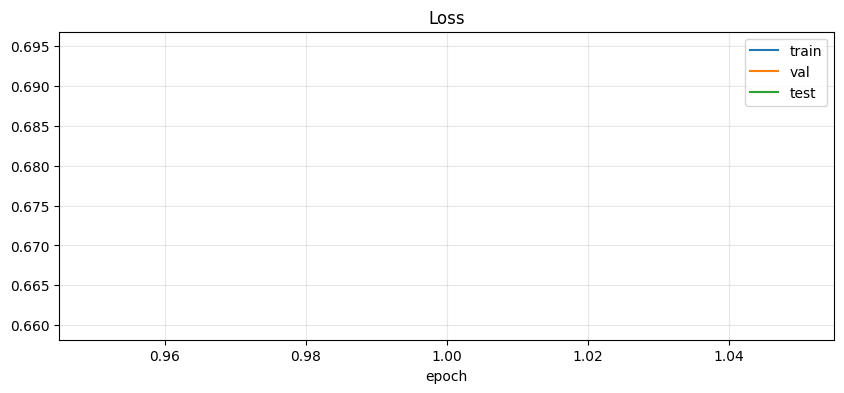

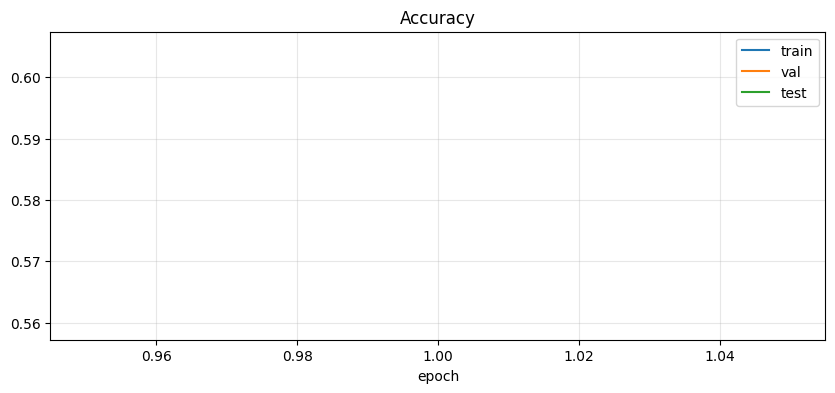

Epoch 2/100
----------
--- Cur phase: train


 10%|▉         | 63/632 [00:26<03:58,  2.39it/s, Loss=0.618271, Corrects=21/32, Accuracy=65.625%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:25<00:00,  2.38it/s, Loss=0.622026, Corrects=19/32, Accuracy=59.375%]


Calculating metrics...
train loss: 0.659222, acc: 0.596816, f05_macro: 0.596677, f1_macro: 0.595987
--- Cur phase: test


100%|██████████| 79/79 [00:11<00:00,  7.05it/s, Loss=1.204645, Corrects=0/1, Accuracy=0.000%]


Calculating metrics...
test loss: 0.639569, acc: 0.620344, f05_macro: 0.620344, f1_macro: 0.620160
--- Cur phase: val


100%|██████████| 70/70 [00:11<00:00,  6.27it/s, Loss=0.676676, Corrects=19/32, Accuracy=59.375%]


Calculating metrics...
val loss: 0.638920, acc: 0.631250, f05_macro: 0.631221, f1_macro: 0.631184


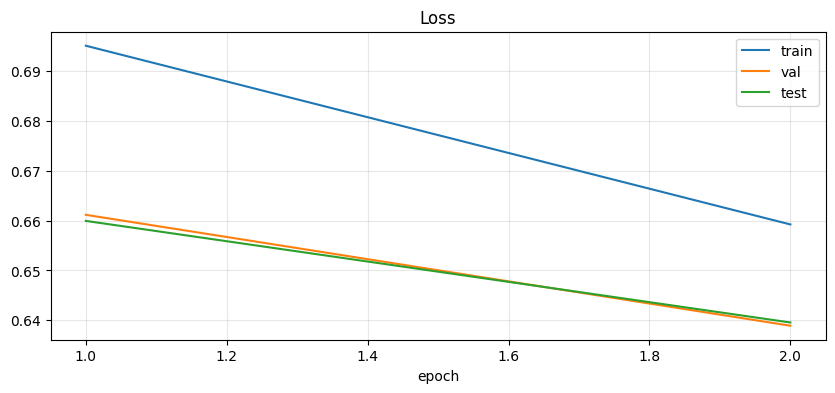

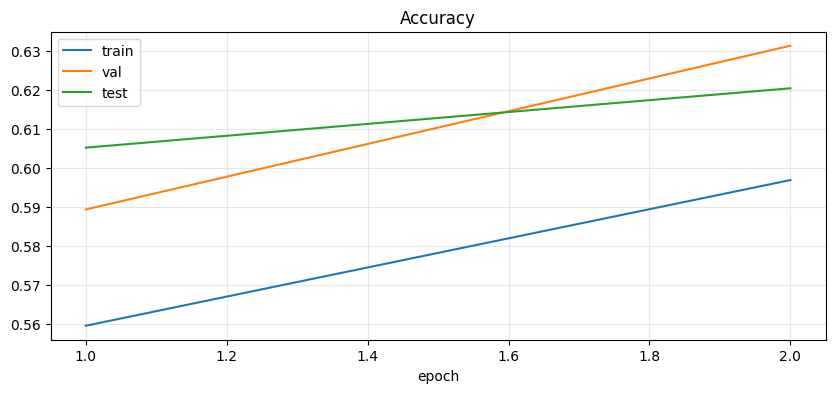

Epoch 3/100
----------
--- Cur phase: train


 72%|███████▏  | 452/632 [03:09<01:15,  2.39it/s, Loss=0.603772, Corrects=24/32, Accuracy=75.000%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:25<00:00,  2.38it/s, Loss=0.702881, Corrects=17/32, Accuracy=53.125%]


Calculating metrics...
train loss: 0.639788, acc: 0.620797, f05_macro: 0.620783, f1_macro: 0.620019
--- Cur phase: test


100%|██████████| 79/79 [00:12<00:00,  6.19it/s, Loss=0.670913, Corrects=1/1, Accuracy=100.000%]


Calculating metrics...
test loss: 0.636743, acc: 0.643973, f05_macro: 0.644008, f1_macro: 0.643660
--- Cur phase: val


100%|██████████| 70/70 [00:11<00:00,  6.11it/s, Loss=0.575434, Corrects=22/32, Accuracy=68.750%]


Calculating metrics...
val loss: 0.651216, acc: 0.616964, f05_macro: 0.617012, f1_macro: 0.616816
p 3921026


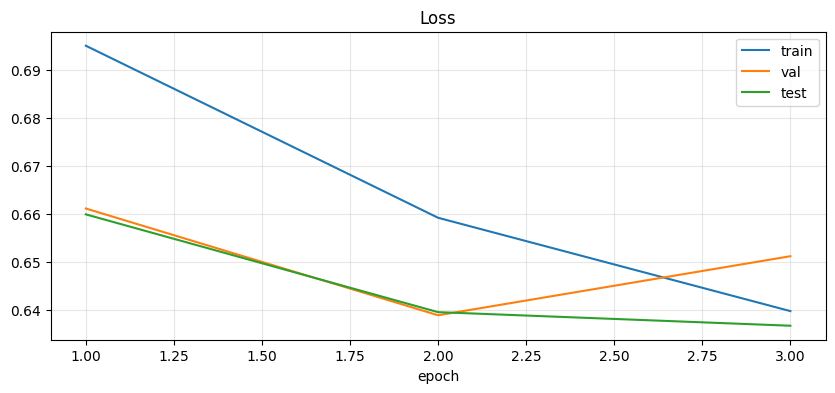

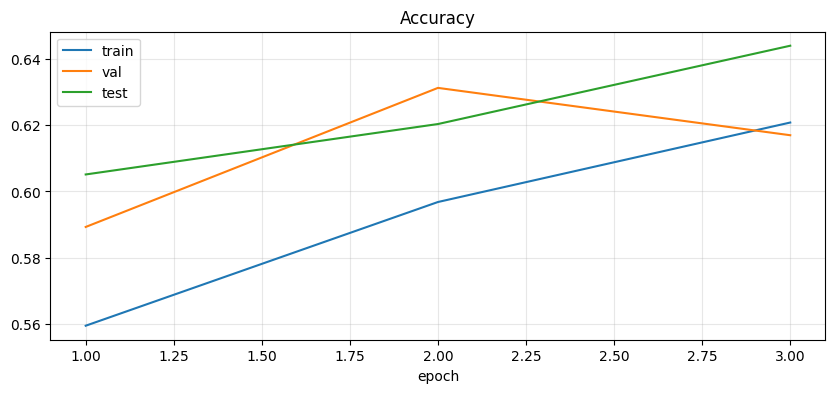

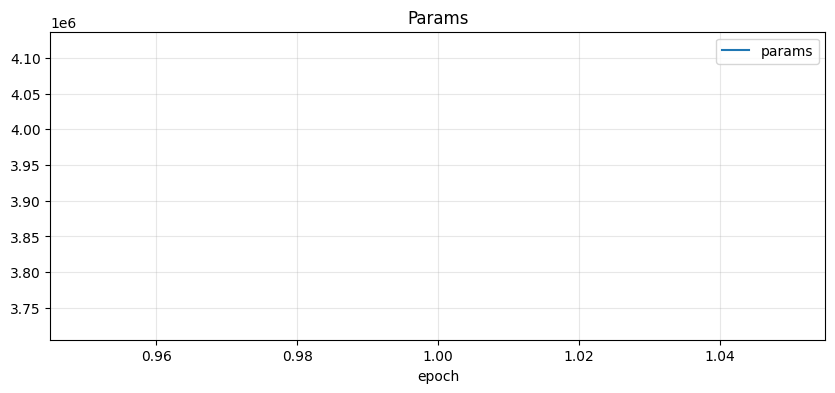

Epoch 4/100
----------
--- Cur phase: train


 47%|████▋     | 299/632 [02:05<02:18,  2.40it/s, Loss=0.632155, Corrects=18/32, Accuracy=56.250%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:25<00:00,  2.38it/s, Loss=0.603810, Corrects=21/32, Accuracy=65.625%]


Calculating metrics...
train loss: 0.631532, acc: 0.629846, f05_macro: 0.629886, f1_macro: 0.629068
--- Cur phase: test


100%|██████████| 79/79 [00:12<00:00,  6.33it/s, Loss=0.819592, Corrects=0/1, Accuracy=0.000%]


Calculating metrics...
test loss: 0.631384, acc: 0.637165, f05_macro: 0.638832, f1_macro: 0.619843
--- Cur phase: val


100%|██████████| 70/70 [00:11<00:00,  6.11it/s, Loss=0.656843, Corrects=16/32, Accuracy=50.000%]


Calculating metrics...
val loss: 0.628784, acc: 0.635714, f05_macro: 0.636523, f1_macro: 0.617407
Проверка условия расширения...
Среднее изменение loss: 0.018987504215467504, порог: 0.005
p 3921026


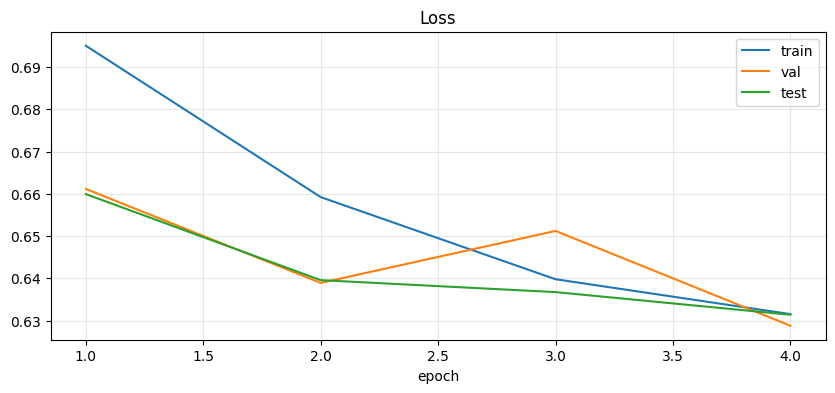

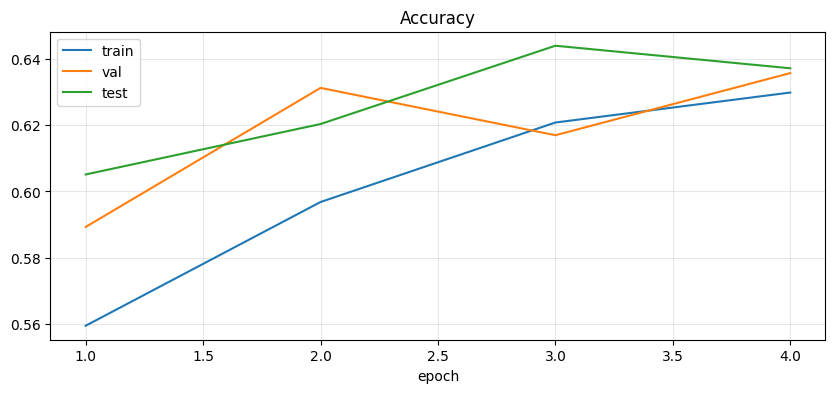

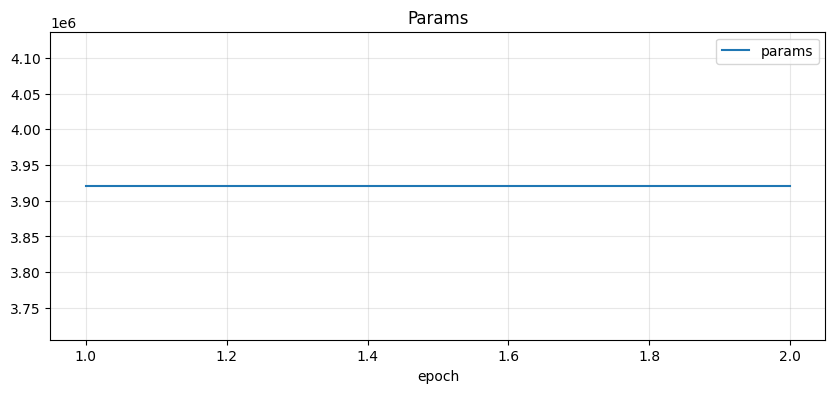

Epoch 5/100
----------
--- Cur phase: train


 90%|█████████ | 571/632 [03:59<00:25,  2.40it/s, Loss=0.566215, Corrects=23/32, Accuracy=71.875%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:25<00:00,  2.38it/s, Loss=0.616242, Corrects=23/32, Accuracy=71.875%]


Calculating metrics...
train loss: 0.625887, acc: 0.641713, f05_macro: 0.641783, f1_macro: 0.641222
--- Cur phase: test


100%|██████████| 79/79 [00:12<00:00,  6.36it/s, Loss=1.014925, Corrects=0/1, Accuracy=0.000%]


Calculating metrics...
test loss: 0.666477, acc: 0.592711, f05_macro: 0.577963, f1_macro: 0.535549
--- Cur phase: val


100%|██████████| 70/70 [00:11<00:00,  6.12it/s, Loss=0.718920, Corrects=18/32, Accuracy=56.250%]


Calculating metrics...
val loss: 0.662386, acc: 0.593304, f05_macro: 0.575820, f1_macro: 0.531251
Проверка условия расширения...
Среднее изменение loss: 0.0227771878242492, порог: 0.005
p 3921026


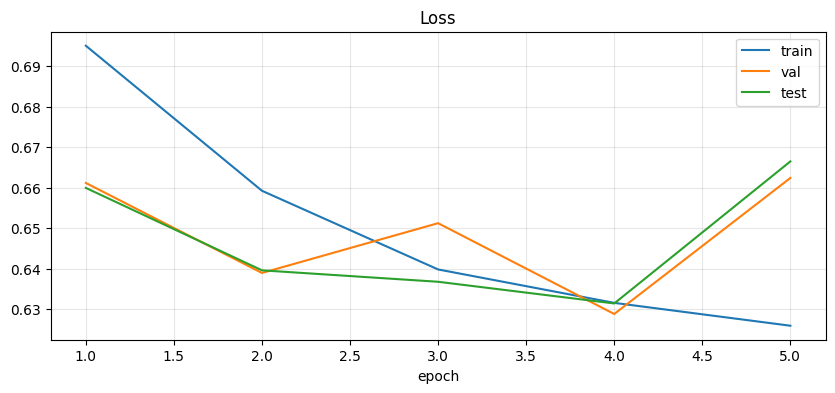

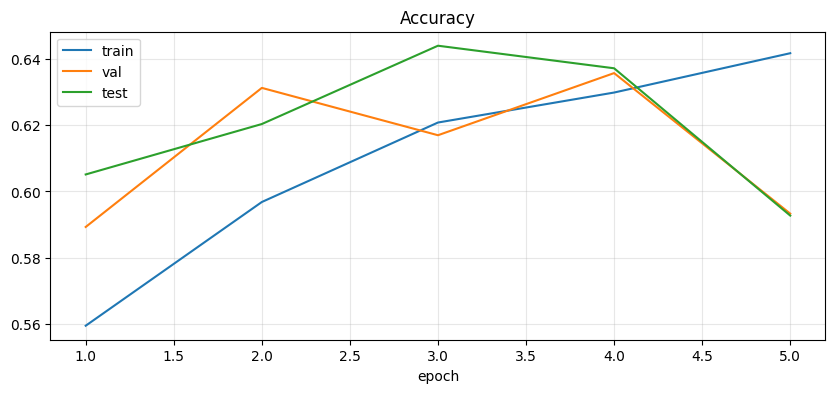

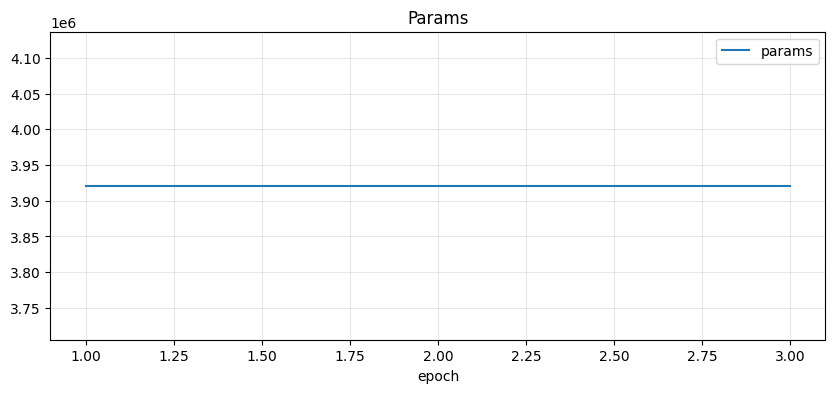

Epoch 6/100
----------
--- Cur phase: train


 25%|██▍       | 157/632 [01:06<03:20,  2.37it/s, Loss=0.544709, Corrects=21/32, Accuracy=65.625%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:25<00:00,  2.38it/s, Loss=0.586105, Corrects=21/32, Accuracy=65.625%]


Calculating metrics...
train loss: 0.618276, acc: 0.651404, f05_macro: 0.651510, f1_macro: 0.650911
--- Cur phase: test


100%|██████████| 79/79 [00:12<00:00,  6.23it/s, Loss=0.885811, Corrects=0/1, Accuracy=0.000%]


Calculating metrics...
test loss: 0.608675, acc: 0.665999, f05_macro: 0.666143, f1_macro: 0.665574
--- Cur phase: val


100%|██████████| 70/70 [00:10<00:00,  6.78it/s, Loss=0.628250, Corrects=22/32, Accuracy=68.750%]


Calculating metrics...
val loss: 0.608423, acc: 0.659375, f05_macro: 0.659501, f1_macro: 0.658242
Проверка условия расширения...
Среднее изменение loss: 0.036666040619214336, порог: 0.005
p 3921026


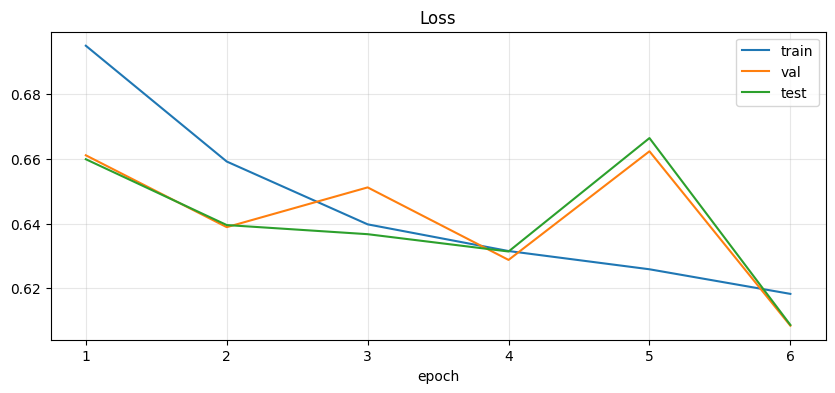

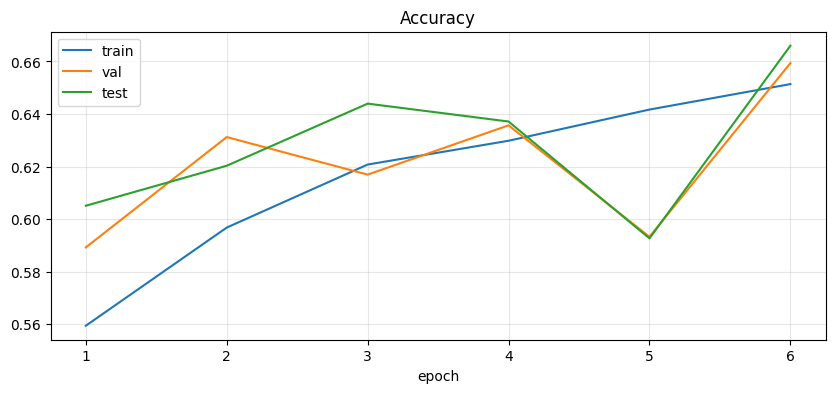

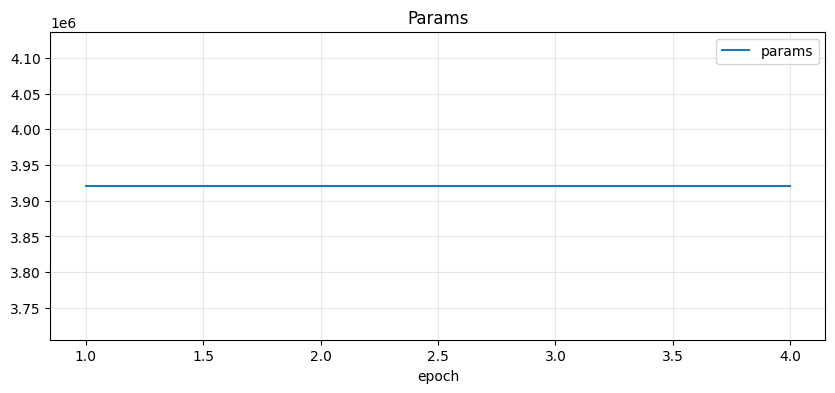

Epoch 7/100
----------
--- Cur phase: train


 99%|█████████▊| 623/632 [04:21<00:03,  2.38it/s, Loss=0.614109, Corrects=20/32, Accuracy=62.500%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:25<00:00,  2.38it/s, Loss=0.709702, Corrects=18/32, Accuracy=56.250%]


Calculating metrics...
train loss: 0.608935, acc: 0.660206, f05_macro: 0.660314, f1_macro: 0.659817
--- Cur phase: test


100%|██████████| 79/79 [00:12<00:00,  6.48it/s, Loss=0.802097, Corrects=0/1, Accuracy=0.000%]


Calculating metrics...
test loss: 0.615346, acc: 0.671205, f05_macro: 0.671356, f1_macro: 0.670759
--- Cur phase: val


100%|██████████| 70/70 [00:11<00:00,  5.87it/s, Loss=0.545424, Corrects=23/32, Accuracy=71.875%]


Calculating metrics...
val loss: 0.610238, acc: 0.660714, f05_macro: 0.660969, f1_macro: 0.660213
Проверка условия расширения...
Среднее изменение loss: 0.029793463718323476, порог: 0.005
p 3921026


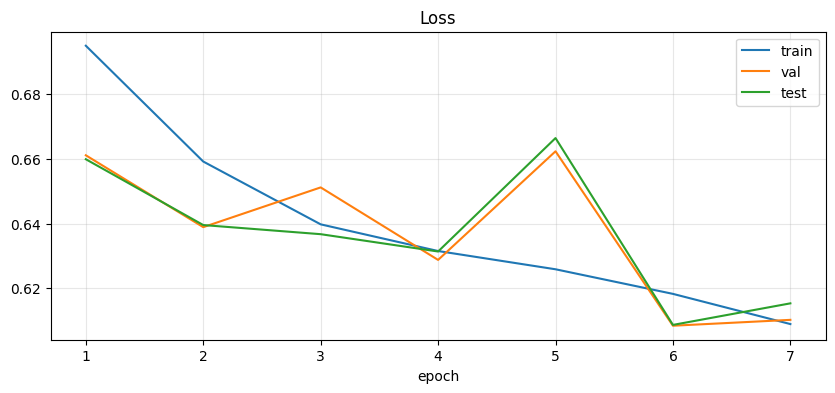

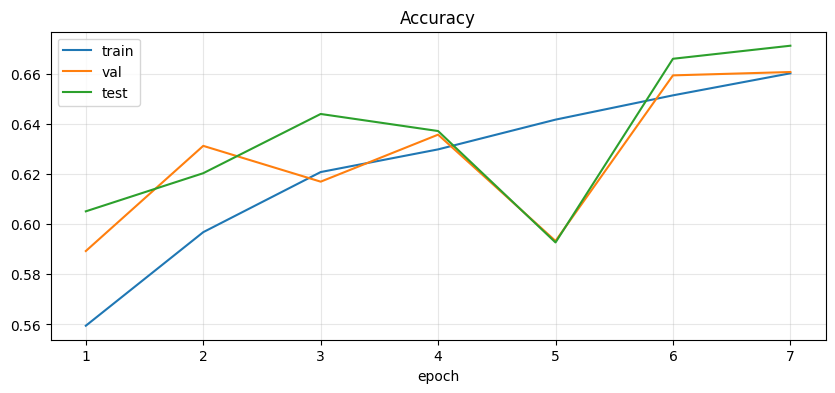

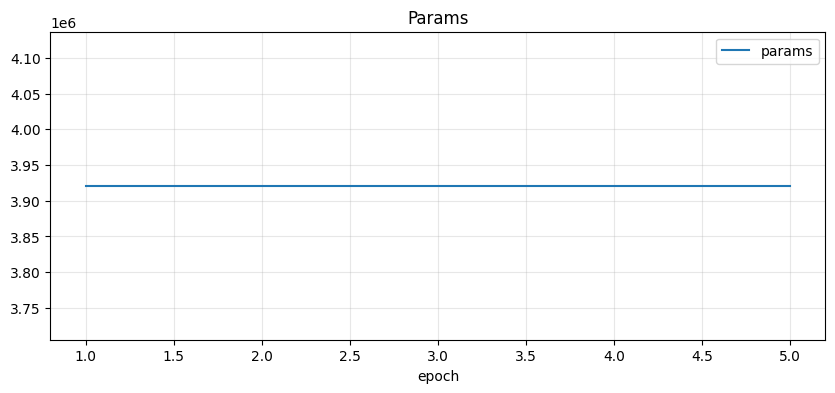

Epoch 8/100
----------
--- Cur phase: train


 17%|█▋        | 108/632 [00:45<03:39,  2.39it/s, Loss=0.712035, Corrects=14/32, Accuracy=43.750%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:25<00:00,  2.38it/s, Loss=0.606982, Corrects=20/32, Accuracy=62.500%]


Calculating metrics...
train loss: 0.605173, acc: 0.665941, f05_macro: 0.666063, f1_macro: 0.665590
--- Cur phase: test


100%|██████████| 79/79 [00:13<00:00,  6.06it/s, Loss=0.722008, Corrects=0/1, Accuracy=0.000%]


Calculating metrics...
test loss: 0.588627, acc: 0.688827, f05_macro: 0.688857, f1_macro: 0.688775
--- Cur phase: val


100%|██████████| 70/70 [00:12<00:00,  5.83it/s, Loss=0.588504, Corrects=20/32, Accuracy=62.500%]


Calculating metrics...
val loss: 0.587539, acc: 0.685268, f05_macro: 0.685262, f1_macro: 0.685182
Проверка условия расширения...
Среднее изменение loss: 0.026158901481401358, порог: 0.005
p 3921026


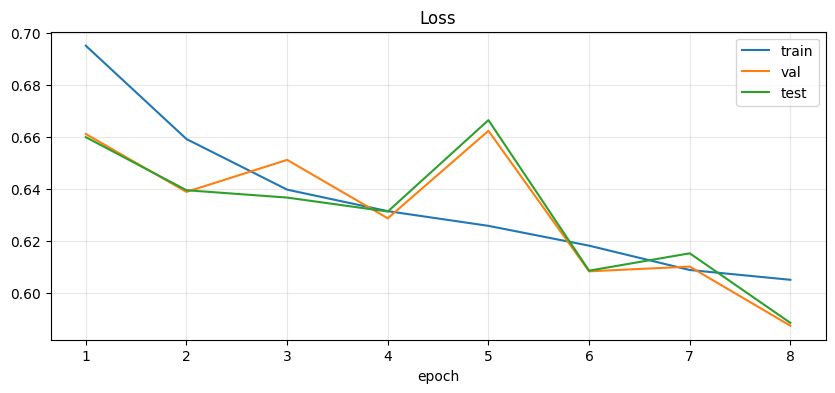

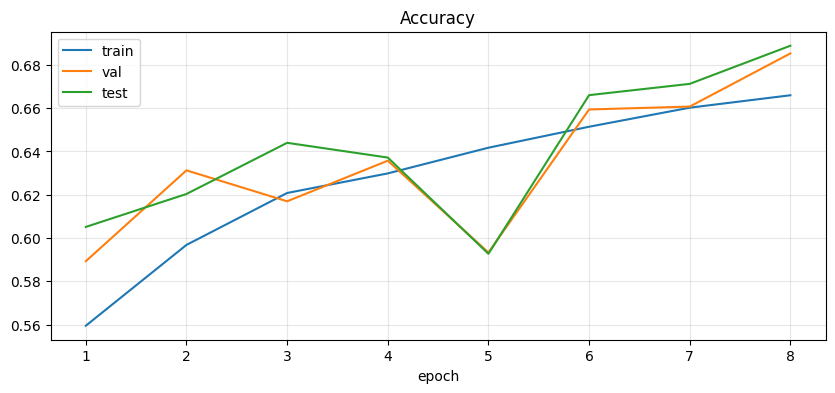

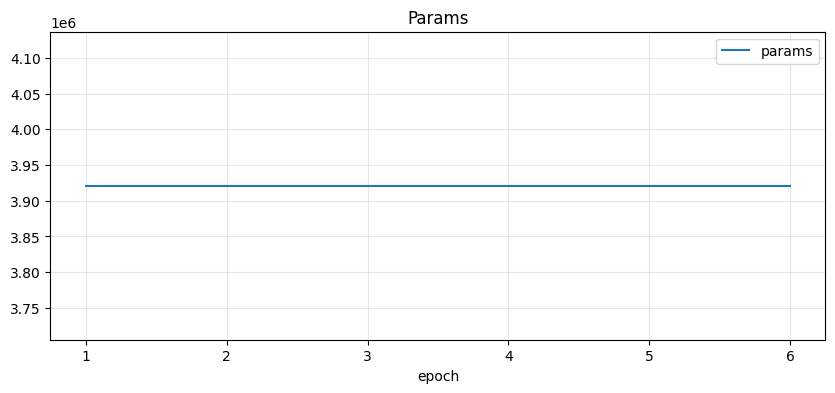

Epoch 9/100
----------
--- Cur phase: train


 17%|█▋        | 105/632 [00:44<03:40,  2.40it/s, Loss=0.516600, Corrects=25/32, Accuracy=78.125%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:25<00:00,  2.38it/s, Loss=0.571277, Corrects=22/32, Accuracy=68.750%]


Calculating metrics...
train loss: 0.594098, acc: 0.676820, f05_macro: 0.676975, f1_macro: 0.676485
--- Cur phase: test


100%|██████████| 79/79 [00:13<00:00,  6.06it/s, Loss=0.657692, Corrects=1/1, Accuracy=100.000%]


Calculating metrics...
test loss: 0.604235, acc: 0.680817, f05_macro: 0.681064, f1_macro: 0.680241
--- Cur phase: val


100%|██████████| 70/70 [00:10<00:00,  6.46it/s, Loss=0.596482, Corrects=23/32, Accuracy=71.875%]


Calculating metrics...
val loss: 0.601933, acc: 0.680357, f05_macro: 0.680656, f1_macro: 0.679949
Проверка условия расширения...
Среднее изменение loss: 0.012969058326312455, порог: 0.005
p 3921026


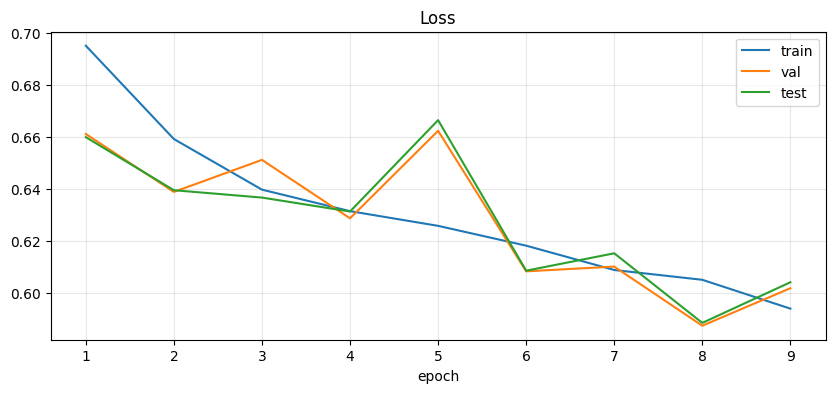

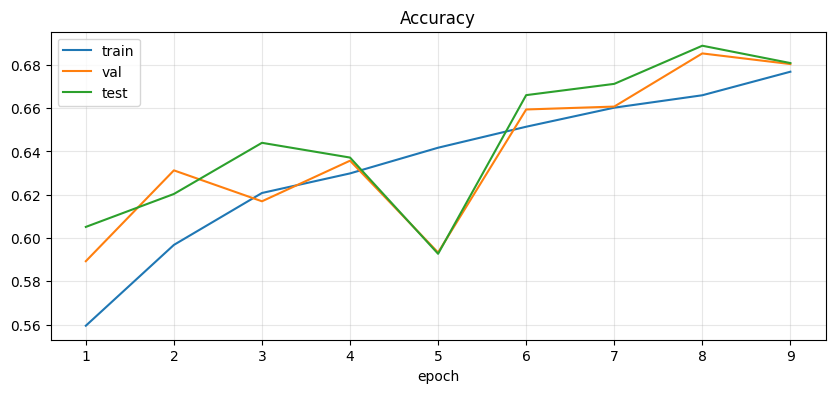

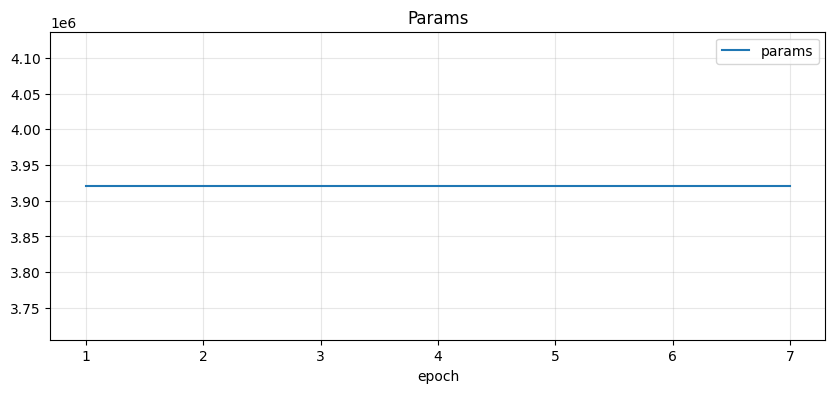

Epoch 10/100
----------
--- Cur phase: train


 23%|██▎       | 145/632 [01:01<03:23,  2.40it/s, Loss=0.458685, Corrects=25/32, Accuracy=78.125%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:25<00:00,  2.38it/s, Loss=0.655771, Corrects=22/32, Accuracy=68.750%]


Calculating metrics...
train loss: 0.586060, acc: 0.686462, f05_macro: 0.686652, f1_macro: 0.686112
--- Cur phase: test


100%|██████████| 79/79 [00:12<00:00,  6.21it/s, Loss=0.336254, Corrects=1/1, Accuracy=100.000%]


Calculating metrics...
test loss: 0.607895, acc: 0.674810, f05_macro: 0.677237, f1_macro: 0.668703
--- Cur phase: val


100%|██████████| 70/70 [00:12<00:00,  5.71it/s, Loss=0.626147, Corrects=21/32, Accuracy=65.625%]


Calculating metrics...
val loss: 0.609726, acc: 0.666964, f05_macro: 0.669356, f1_macro: 0.661046
Проверка условия расширения...
Среднее изменение loss: 0.014961693968091697, порог: 0.005
p 3921026


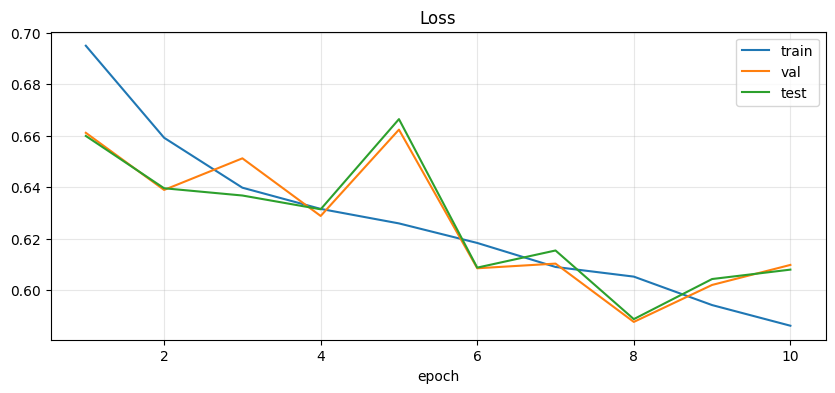

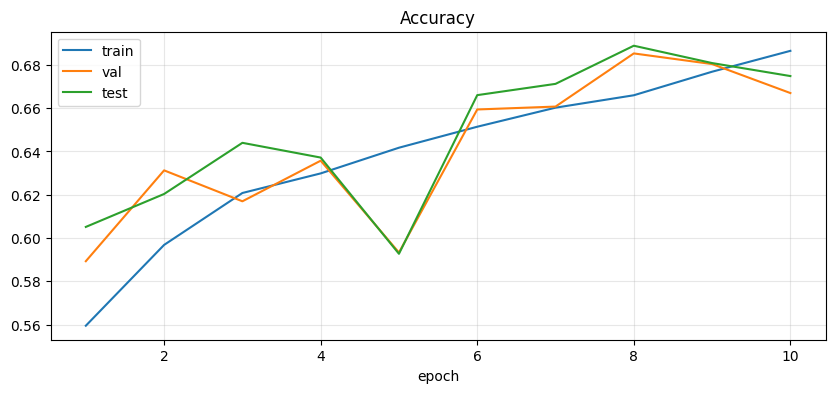

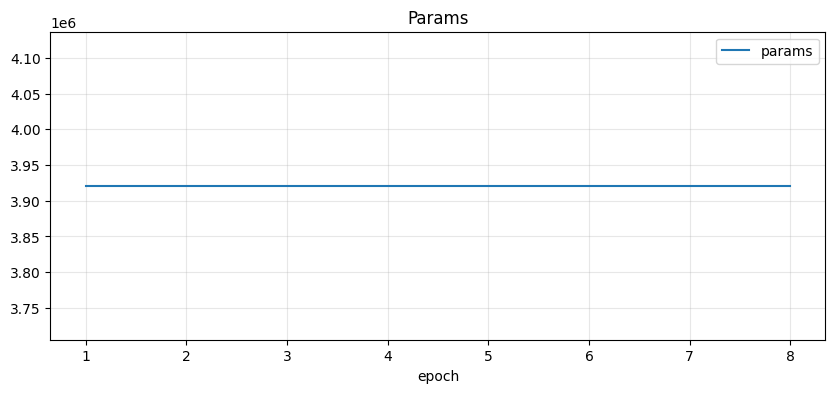

Epoch 11/100
----------
--- Cur phase: train


  1%|          | 6/632 [00:02<04:33,  2.29it/s, Loss=0.611652, Corrects=20/32, Accuracy=62.500%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:25<00:00,  2.38it/s, Loss=0.580079, Corrects=23/32, Accuracy=71.875%]


Calculating metrics...
train loss: 0.581844, acc: 0.687945, f05_macro: 0.688170, f1_macro: 0.687546
--- Cur phase: test


100%|██████████| 79/79 [00:13<00:00,  5.89it/s, Loss=0.622240, Corrects=1/1, Accuracy=100.000%]


Calculating metrics...
test loss: 0.566308, acc: 0.710052, f05_macro: 0.710730, f1_macro: 0.709177
--- Cur phase: val


100%|██████████| 70/70 [00:12<00:00,  5.78it/s, Loss=0.542672, Corrects=21/32, Accuracy=65.625%]


Calculating metrics...
val loss: 0.577917, acc: 0.693304, f05_macro: 0.693908, f1_macro: 0.691866
Проверка условия расширения...
Среднее изменение loss: 0.01799832298642116, порог: 0.005
p 3921026


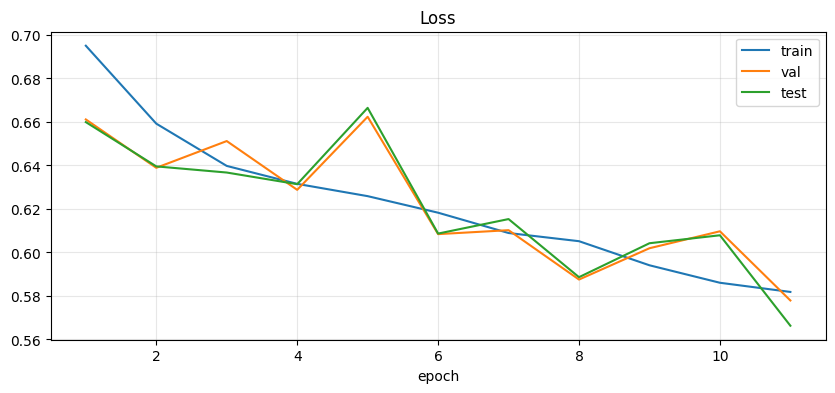

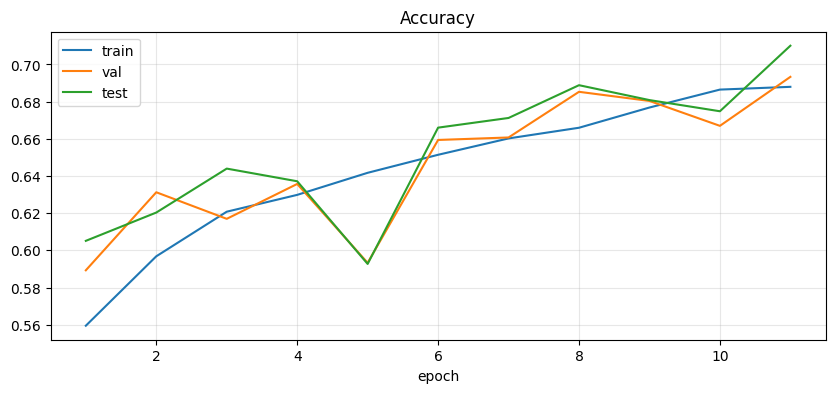

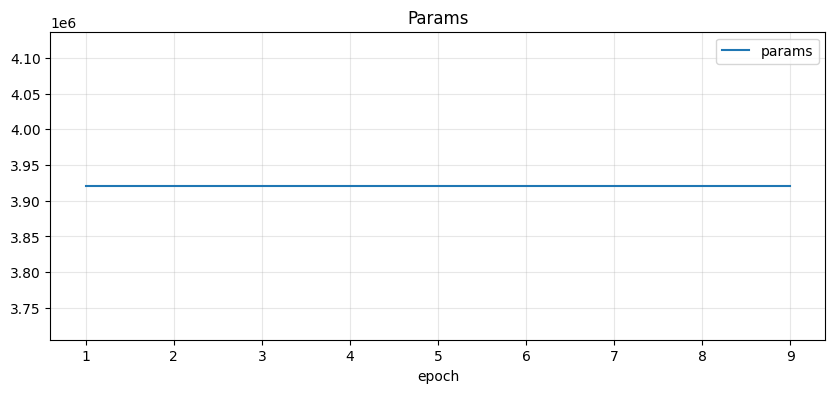

Epoch 12/100
----------
--- Cur phase: train


 39%|███▉      | 246/632 [01:43<02:41,  2.39it/s, Loss=0.684474, Corrects=19/32, Accuracy=59.375%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:25<00:00,  2.38it/s, Loss=0.682596, Corrects=20/32, Accuracy=62.500%]


Calculating metrics...
train loss: 0.575836, acc: 0.695312, f05_macro: 0.695500, f1_macro: 0.695022
--- Cur phase: test


100%|██████████| 79/79 [00:13<00:00,  6.07it/s, Loss=0.419243, Corrects=1/1, Accuracy=100.000%]


Calculating metrics...
test loss: 0.584468, acc: 0.703244, f05_macro: 0.705516, f1_macro: 0.699889
--- Cur phase: val


100%|██████████| 70/70 [00:12<00:00,  5.75it/s, Loss=0.499257, Corrects=24/32, Accuracy=75.000%]


Calculating metrics...
val loss: 0.597319, acc: 0.673214, f05_macro: 0.675315, f1_macro: 0.668752
Проверка условия расширения...
Среднее изменение loss: 0.019667750313168548, порог: 0.005
p 3921026


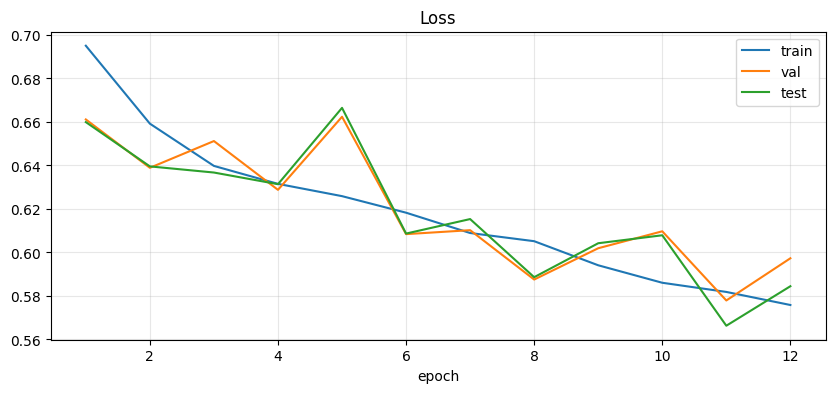

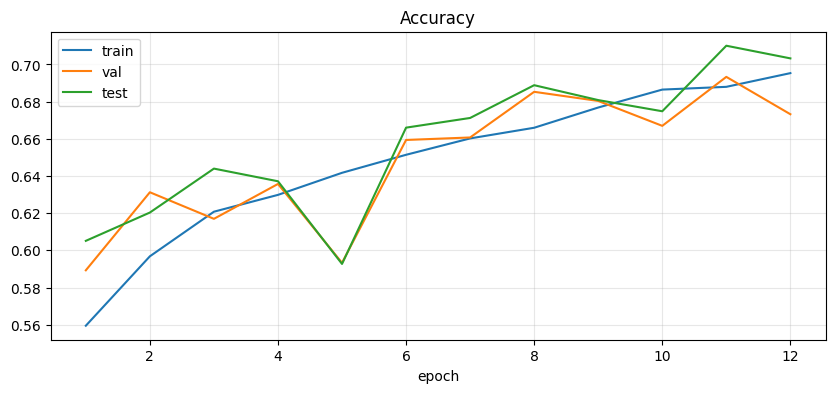

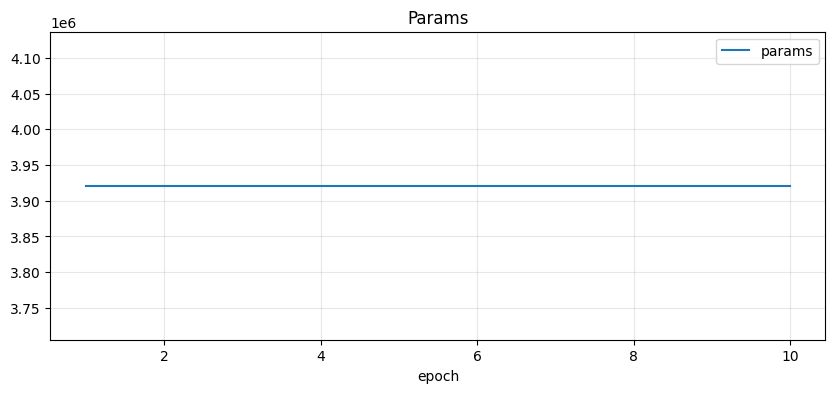

Epoch 13/100
----------
--- Cur phase: train


 45%|████▌     | 287/632 [02:00<02:24,  2.38it/s, Loss=0.530544, Corrects=23/32, Accuracy=71.875%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:25<00:00,  2.38it/s, Loss=0.464147, Corrects=23/32, Accuracy=71.875%]


Calculating metrics...
train loss: 0.569332, acc: 0.698972, f05_macro: 0.699156, f1_macro: 0.698706
--- Cur phase: test


100%|██████████| 79/79 [00:14<00:00,  5.63it/s, Loss=0.396633, Corrects=1/1, Accuracy=100.000%]


Calculating metrics...
test loss: 0.564987, acc: 0.709251, f05_macro: 0.709399, f1_macro: 0.709042
--- Cur phase: val


100%|██████████| 70/70 [00:12<00:00,  5.48it/s, Loss=0.516799, Corrects=24/32, Accuracy=75.000%]


Calculating metrics...
val loss: 0.568150, acc: 0.706250, f05_macro: 0.706508, f1_macro: 0.706025
Проверка условия расширения...
Среднее изменение loss: 0.026793323528199037, порог: 0.005
p 3921026


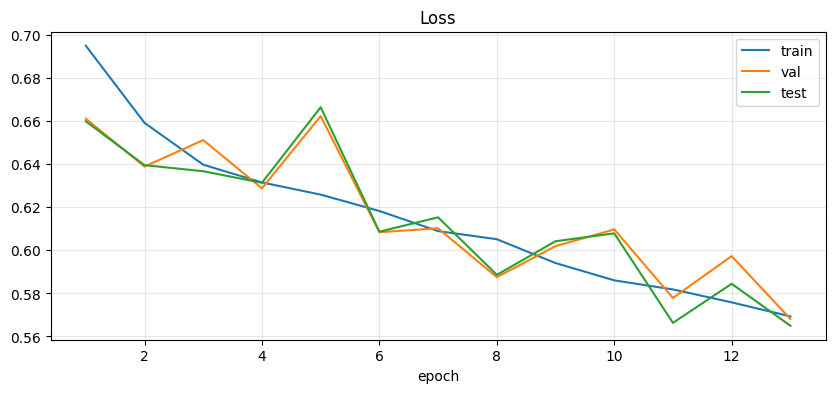

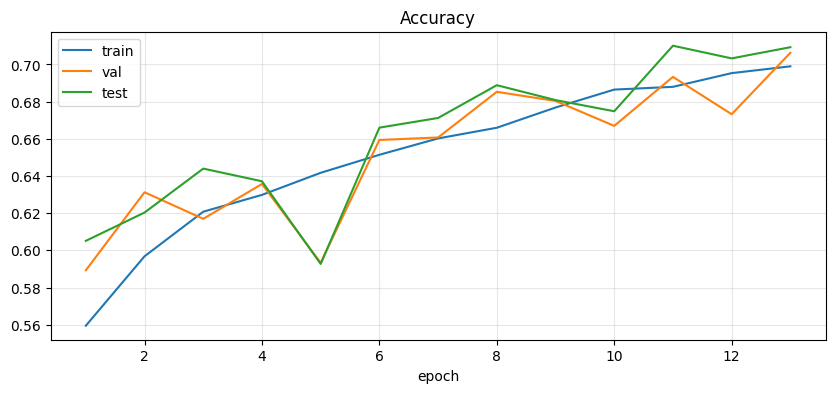

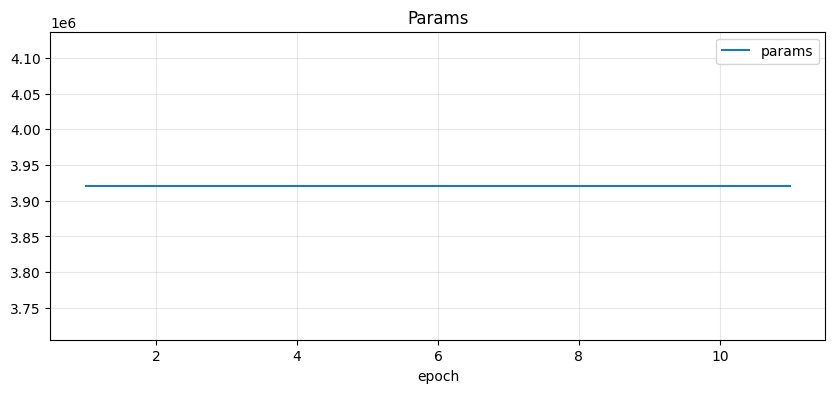

Epoch 14/100
----------
--- Cur phase: train


  6%|▌         | 38/632 [00:16<04:10,  2.37it/s, Loss=0.568003, Corrects=21/32, Accuracy=65.625%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:26<00:00,  2.38it/s, Loss=0.463860, Corrects=22/32, Accuracy=68.750%]


Calculating metrics...
train loss: 0.561314, acc: 0.705845, f05_macro: 0.706036, f1_macro: 0.705607
--- Cur phase: test


100%|██████████| 79/79 [00:13<00:00,  5.77it/s, Loss=0.325227, Corrects=1/1, Accuracy=100.000%]


Calculating metrics...
test loss: 0.574217, acc: 0.700040, f05_macro: 0.702322, f1_macro: 0.696491
--- Cur phase: val


100%|██████████| 70/70 [00:12<00:00,  5.54it/s, Loss=0.539469, Corrects=23/32, Accuracy=71.875%]


Calculating metrics...
val loss: 0.583553, acc: 0.691071, f05_macro: 0.693218, f1_macro: 0.687837
Проверка условия расширения...
Среднее изменение loss: 0.02132477391333813, порог: 0.005
p 3921026


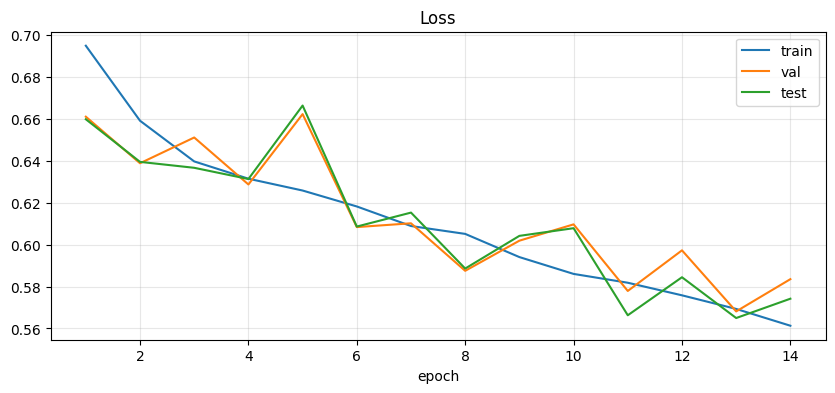

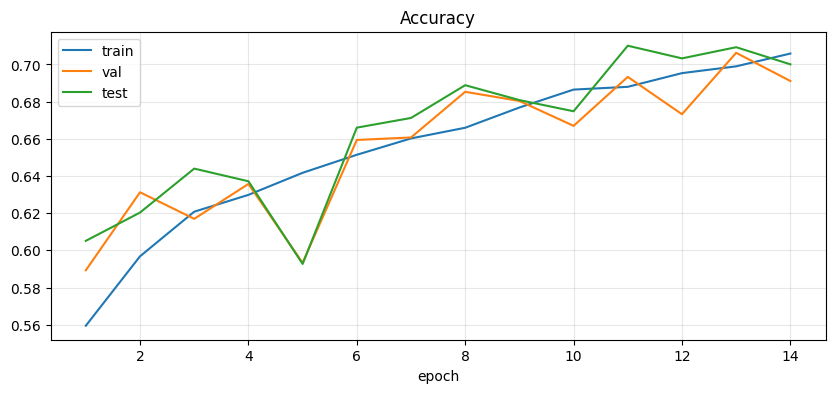

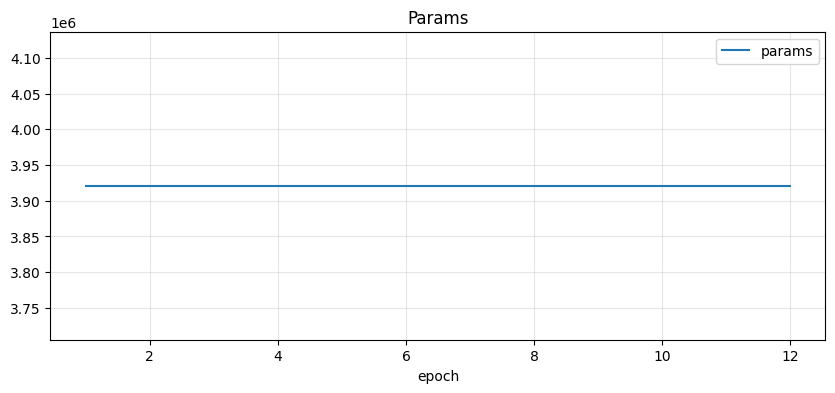

Epoch 15/100
----------
--- Cur phase: train


  9%|▉         | 60/632 [00:25<04:01,  2.37it/s, Loss=0.471737, Corrects=25/32, Accuracy=78.125%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:26<00:00,  2.37it/s, Loss=0.575628, Corrects=21/32, Accuracy=65.625%]


Calculating metrics...
train loss: 0.556905, acc: 0.711135, f05_macro: 0.711312, f1_macro: 0.710915
--- Cur phase: test


100%|██████████| 79/79 [00:13<00:00,  5.78it/s, Loss=0.199011, Corrects=1/1, Accuracy=100.000%]


Calculating metrics...
test loss: 0.560559, acc: 0.701241, f05_macro: 0.701311, f1_macro: 0.701126
--- Cur phase: val


100%|██████████| 70/70 [00:12<00:00,  5.53it/s, Loss=0.530576, Corrects=23/32, Accuracy=71.875%]


Calculating metrics...
val loss: 0.568710, acc: 0.696875, f05_macro: 0.697040, f1_macro: 0.696730
Проверка условия расширения...
Среднее изменение loss: 0.019804953109650397, порог: 0.005
p 3921026


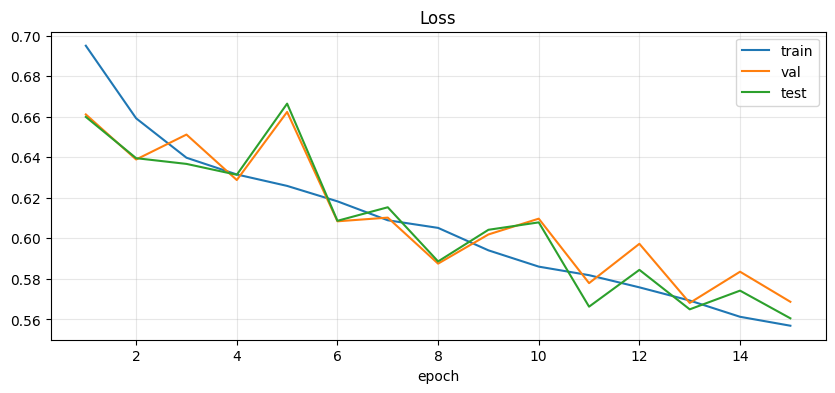

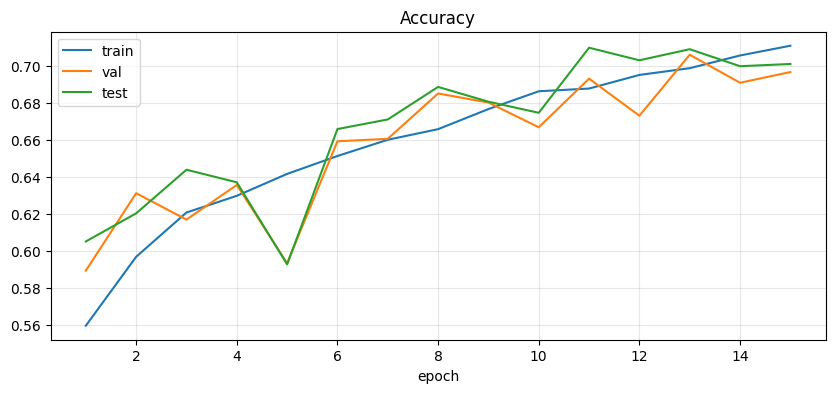

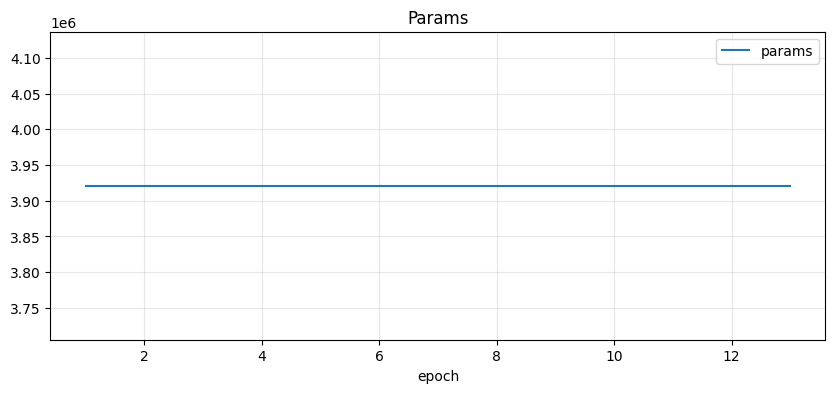

Epoch 16/100
----------
--- Cur phase: train


 12%|█▏        | 77/632 [00:33<03:55,  2.35it/s, Loss=0.577553, Corrects=20/32, Accuracy=62.500%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:26<00:00,  2.37it/s, Loss=0.510309, Corrects=23/32, Accuracy=71.875%]


Calculating metrics...
train loss: 0.551660, acc: 0.713311, f05_macro: 0.713507, f1_macro: 0.713073
--- Cur phase: test


100%|██████████| 79/79 [00:14<00:00,  5.53it/s, Loss=0.394453, Corrects=1/1, Accuracy=100.000%]


Calculating metrics...
test loss: 0.563030, acc: 0.707249, f05_macro: 0.707843, f1_macro: 0.706403
--- Cur phase: val


100%|██████████| 70/70 [00:12<00:00,  5.62it/s, Loss=0.551062, Corrects=21/32, Accuracy=65.625%]


Calculating metrics...
val loss: 0.557249, acc: 0.705804, f05_macro: 0.706624, f1_macro: 0.704914
Проверка условия расширения...
Среднее изменение loss: 0.013902342461404352, порог: 0.005
p 3921026


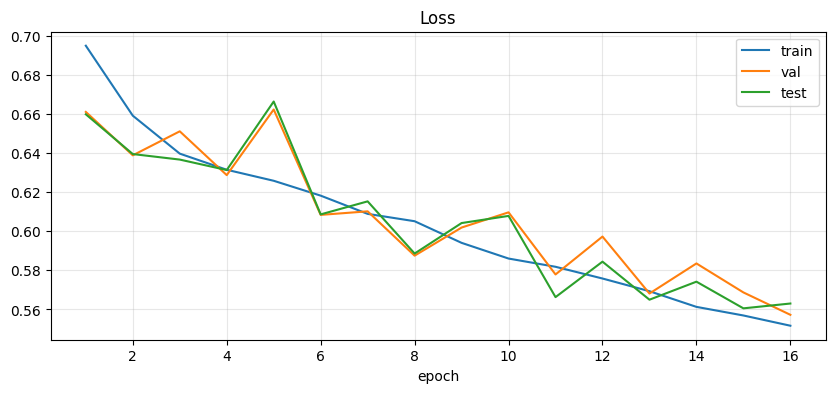

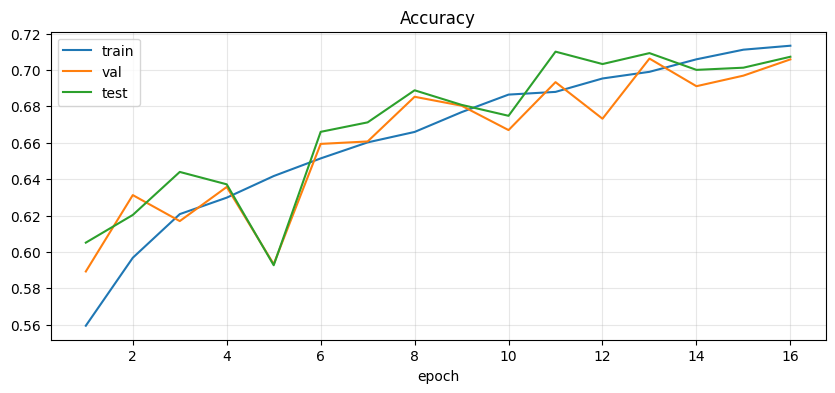

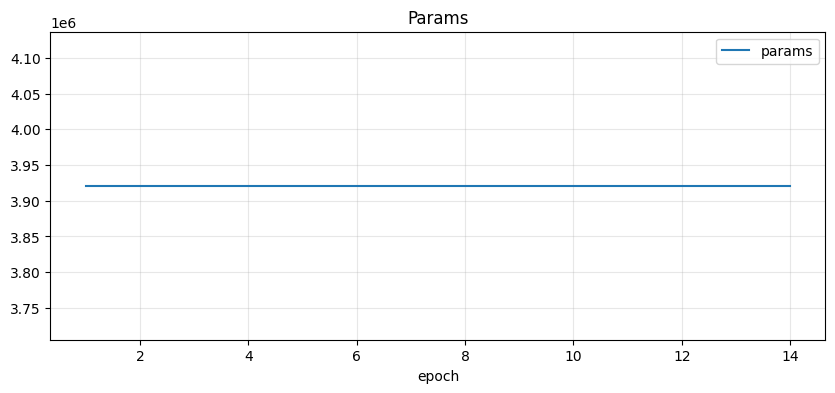

Epoch 17/100
----------
--- Cur phase: train


 47%|████▋     | 299/632 [02:06<02:20,  2.38it/s, Loss=0.627411, Corrects=21/32, Accuracy=65.625%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:26<00:00,  2.37it/s, Loss=0.563540, Corrects=22/32, Accuracy=68.750%]


Calculating metrics...
train loss: 0.539916, acc: 0.726513, f05_macro: 0.726643, f1_macro: 0.726392
--- Cur phase: test


100%|██████████| 79/79 [00:14<00:00,  5.48it/s, Loss=0.803410, Corrects=0/1, Accuracy=0.000%]


Calculating metrics...
test loss: 0.604298, acc: 0.666400, f05_macro: 0.674240, f1_macro: 0.644481
--- Cur phase: val


100%|██████████| 70/70 [00:13<00:00,  5.24it/s, Loss=0.753082, Corrects=20/32, Accuracy=62.500%]


Calculating metrics...
val loss: 0.607608, acc: 0.675893, f05_macro: 0.685362, f1_macro: 0.652774
Проверка условия расширения...
Среднее изменение loss: 0.02555443431649888, порог: 0.005
p 3921026


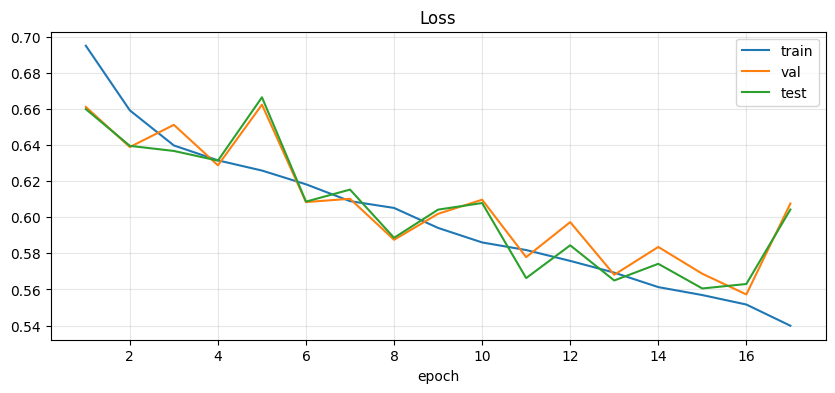

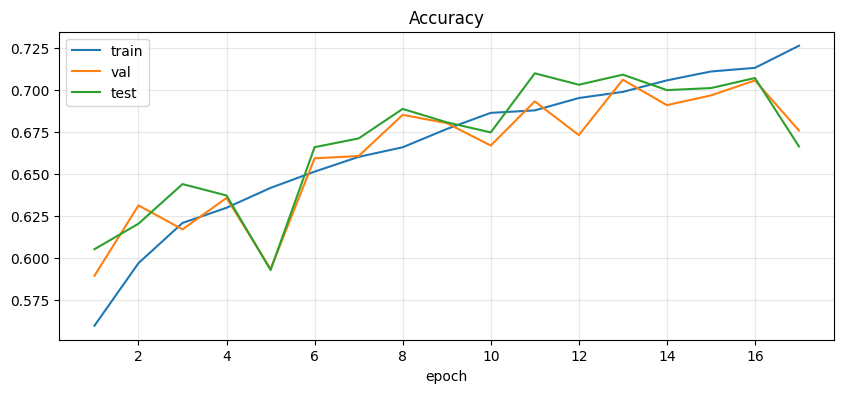

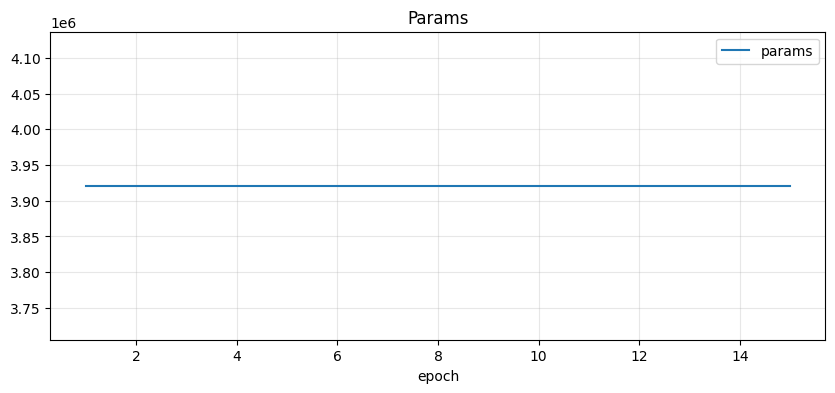

Epoch 18/100
----------
--- Cur phase: train


 13%|█▎        | 83/632 [00:35<03:51,  2.37it/s, Loss=0.621174, Corrects=24/32, Accuracy=75.000%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:26<00:00,  2.37it/s, Loss=0.437193, Corrects=24/32, Accuracy=75.000%]


Calculating metrics...
train loss: 0.535523, acc: 0.728788, f05_macro: 0.728997, f1_macro: 0.728588
--- Cur phase: test


100%|██████████| 79/79 [00:14<00:00,  5.36it/s, Loss=0.435431, Corrects=1/1, Accuracy=100.000%]


Calculating metrics...
test loss: 0.544663, acc: 0.721266, f05_macro: 0.723813, f1_macro: 0.718466
--- Cur phase: val


100%|██████████| 70/70 [00:13<00:00,  5.15it/s, Loss=0.546333, Corrects=25/32, Accuracy=78.125%]


Calculating metrics...
val loss: 0.551733, acc: 0.725000, f05_macro: 0.727358, f1_macro: 0.722121
Проверка условия расширения...
Среднее изменение loss: 0.03923194784493674, порог: 0.005
p 3921026


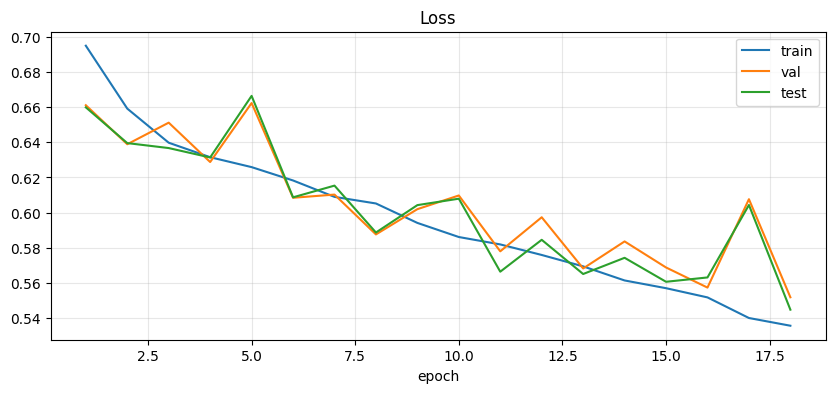

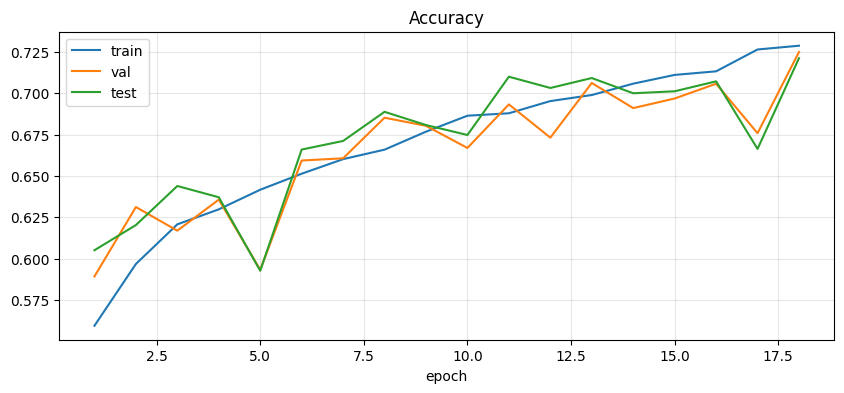

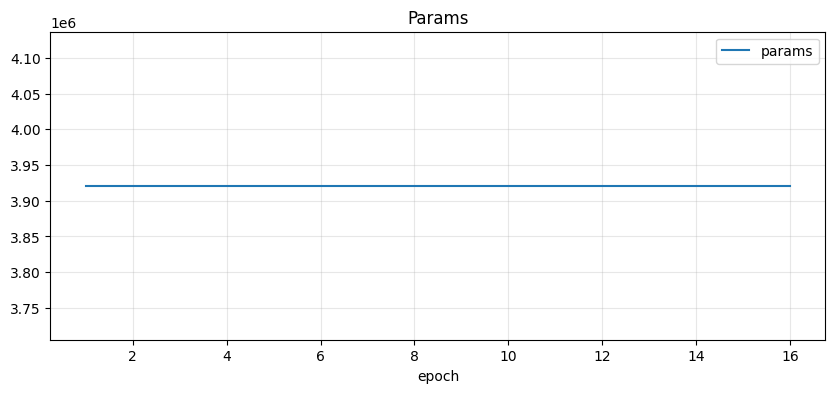

Epoch 19/100
----------
--- Cur phase: train


 80%|███████▉  | 505/632 [03:33<00:53,  2.37it/s, Loss=0.499547, Corrects=25/32, Accuracy=78.125%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:26<00:00,  2.37it/s, Loss=0.582851, Corrects=21/32, Accuracy=65.625%]


Calculating metrics...
train loss: 0.531953, acc: 0.731507, f05_macro: 0.731678, f1_macro: 0.731352
--- Cur phase: test


100%|██████████| 79/79 [00:14<00:00,  5.43it/s, Loss=0.264726, Corrects=1/1, Accuracy=100.000%]


Calculating metrics...
test loss: 0.554936, acc: 0.702443, f05_macro: 0.707373, f1_macro: 0.695388
--- Cur phase: val


100%|██████████| 70/70 [00:13<00:00,  5.31it/s, Loss=0.574787, Corrects=23/32, Accuracy=71.875%]


Calculating metrics...
val loss: 0.546298, acc: 0.709821, f05_macro: 0.715583, f1_macro: 0.701682
Проверка условия расширения...
Среднее изменение loss: 0.0372228457814171, порог: 0.005
p 3921026


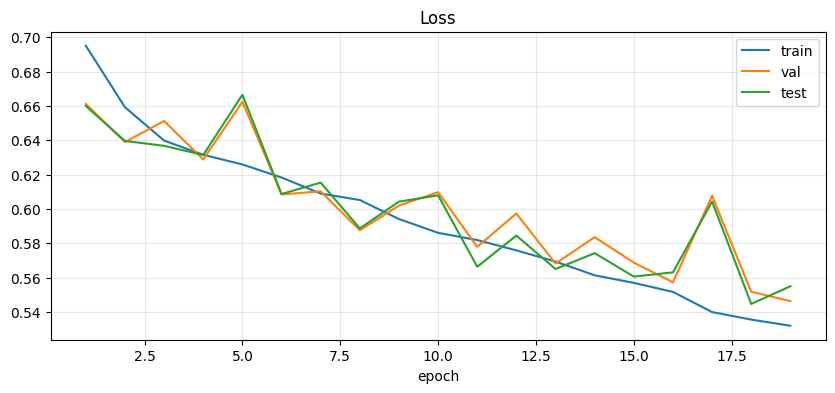

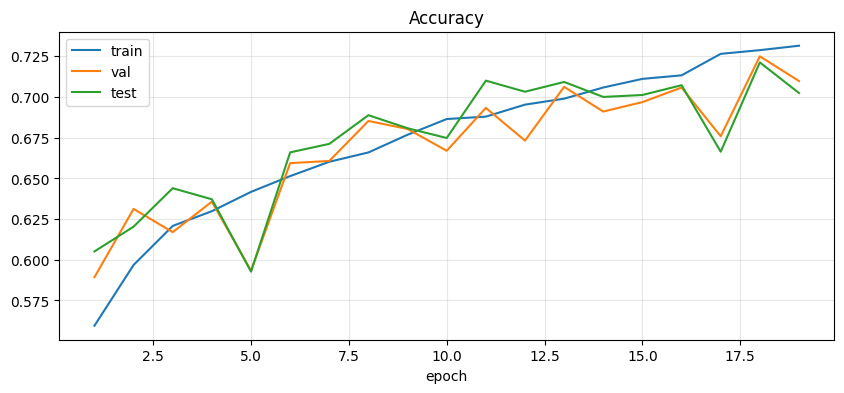

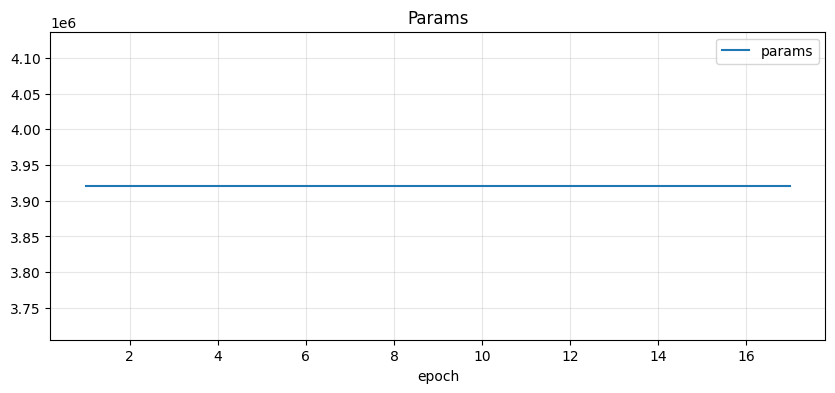

Epoch 20/100
----------
--- Cur phase: train


 21%|██        | 134/632 [00:56<03:27,  2.40it/s, Loss=0.418764, Corrects=28/32, Accuracy=87.500%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:26<00:00,  2.37it/s, Loss=0.564267, Corrects=23/32, Accuracy=71.875%]


Calculating metrics...
train loss: 0.522420, acc: 0.740309, f05_macro: 0.740449, f1_macro: 0.740190
--- Cur phase: test


100%|██████████| 79/79 [00:14<00:00,  5.44it/s, Loss=0.582898, Corrects=1/1, Accuracy=100.000%]


Calculating metrics...
test loss: 0.606858, acc: 0.683220, f05_macro: 0.693243, f1_macro: 0.664082
--- Cur phase: val


100%|██████████| 70/70 [00:13<00:00,  5.28it/s, Loss=0.563476, Corrects=22/32, Accuracy=68.750%]


Calculating metrics...
val loss: 0.620308, acc: 0.680357, f05_macro: 0.689204, f1_macro: 0.660479
Проверка условия расширения...
Среднее изменение loss: 0.04510635974861329, порог: 0.005
p 3921026


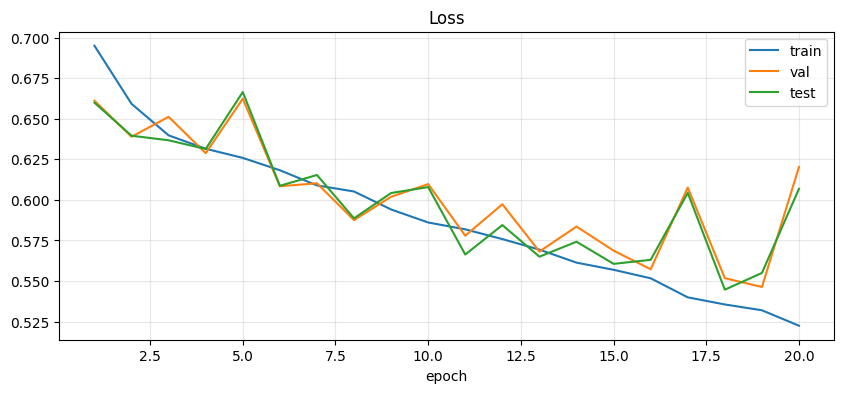

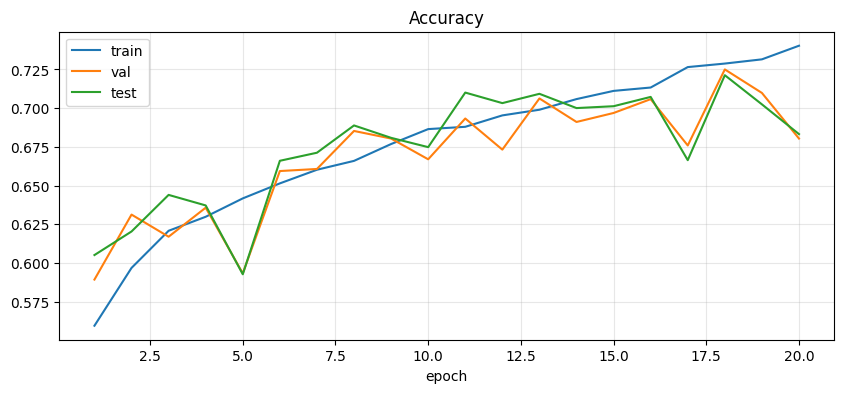

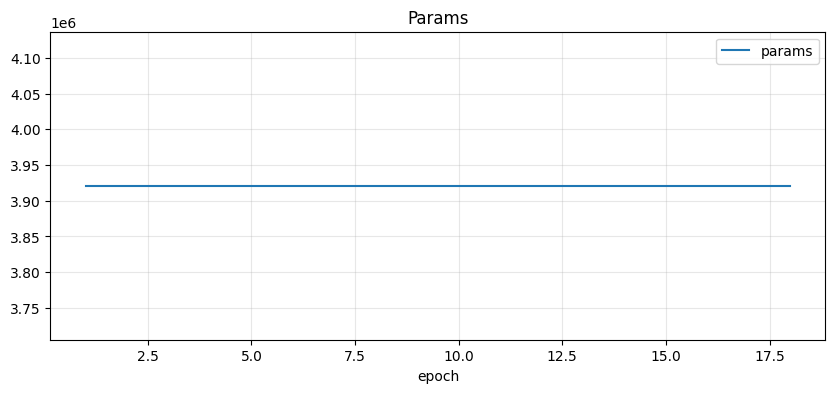

Epoch 21/100
----------
--- Cur phase: train


 58%|█████▊    | 368/632 [02:35<01:50,  2.39it/s, Loss=0.484846, Corrects=25/32, Accuracy=78.125%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:27<00:00,  2.37it/s, Loss=0.444862, Corrects=27/32, Accuracy=84.375%]


Calculating metrics...
train loss: 0.516526, acc: 0.745500, f05_macro: 0.745673, f1_macro: 0.745370
--- Cur phase: test


100%|██████████| 79/79 [00:14<00:00,  5.42it/s, Loss=0.120005, Corrects=1/1, Accuracy=100.000%]


Calculating metrics...
test loss: 0.533188, acc: 0.732078, f05_macro: 0.732543, f1_macro: 0.731613
--- Cur phase: val


100%|██████████| 70/70 [00:13<00:00,  5.31it/s, Loss=0.459867, Corrects=24/32, Accuracy=75.000%]


Calculating metrics...
val loss: 0.541769, acc: 0.734375, f05_macro: 0.734777, f1_macro: 0.734108
Проверка условия расширения...
Среднее изменение loss: 0.05266112067869736, порог: 0.005
p 3921026


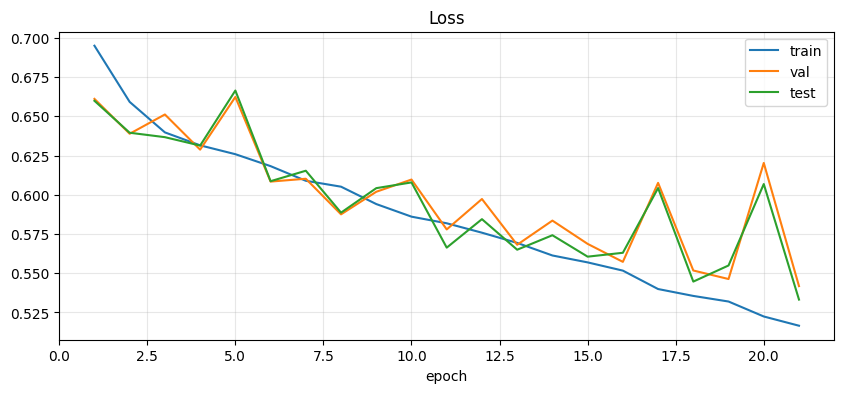

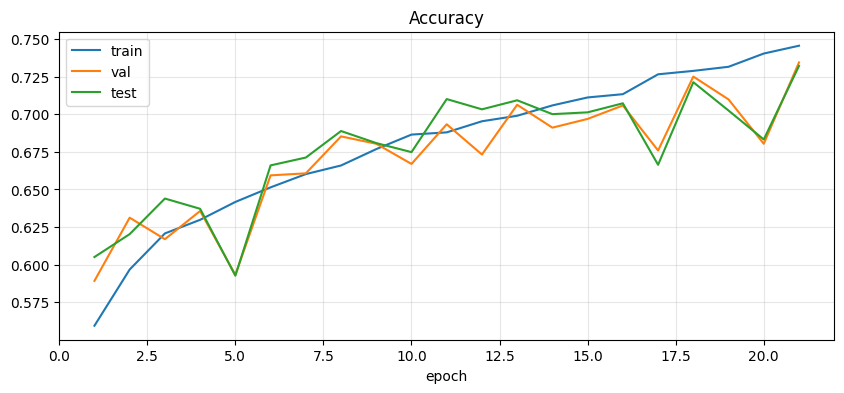

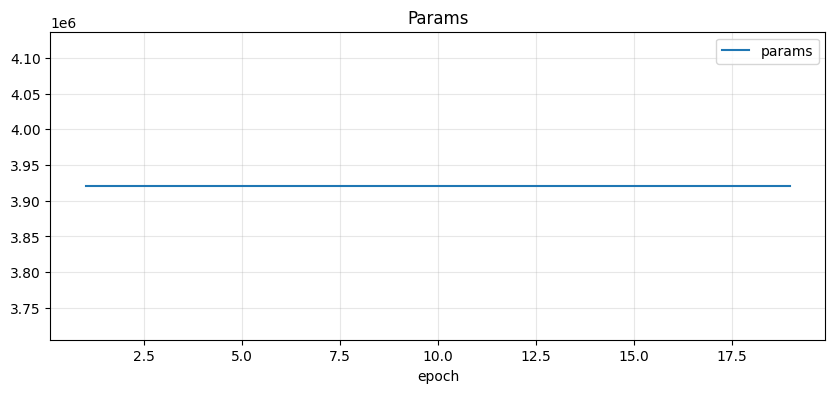

Epoch 22/100
----------
--- Cur phase: train


 99%|█████████▊| 623/632 [04:22<00:03,  2.38it/s, Loss=0.540765, Corrects=26/32, Accuracy=81.250%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:26<00:00,  2.37it/s, Loss=0.569691, Corrects=25/32, Accuracy=78.125%]


Calculating metrics...
train loss: 0.512221, acc: 0.744165, f05_macro: 0.744400, f1_macro: 0.743975
--- Cur phase: test


100%|██████████| 79/79 [00:14<00:00,  5.33it/s, Loss=0.272590, Corrects=1/1, Accuracy=100.000%]


Calculating metrics...
test loss: 0.534792, acc: 0.722066, f05_macro: 0.723116, f1_macro: 0.720877
--- Cur phase: val


100%|██████████| 70/70 [00:12<00:00,  5.39it/s, Loss=0.471669, Corrects=24/32, Accuracy=75.000%]


Calculating metrics...
val loss: 0.537468, acc: 0.725893, f05_macro: 0.726808, f1_macro: 0.725130
Проверка условия расширения...
Среднее изменение loss: 0.052283355451765545, порог: 0.005
p 3921026


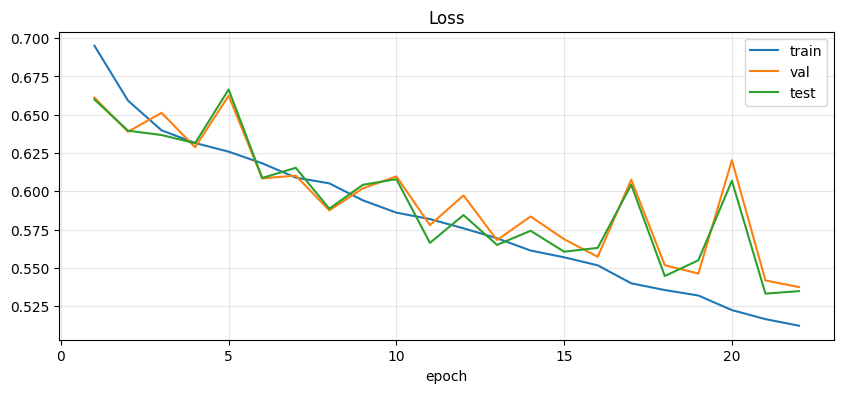

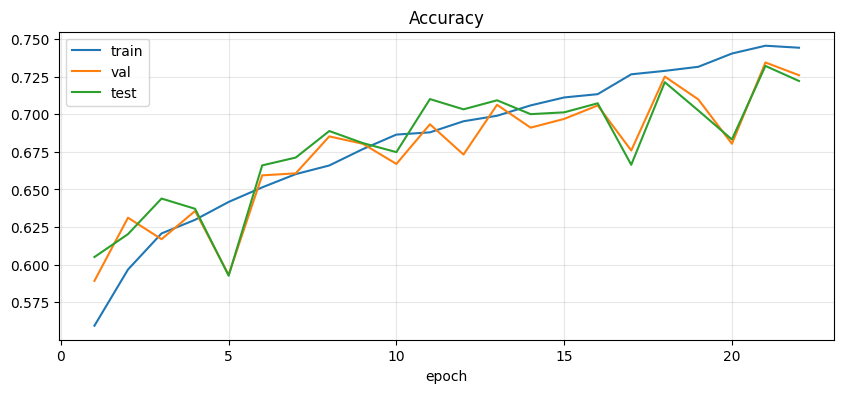

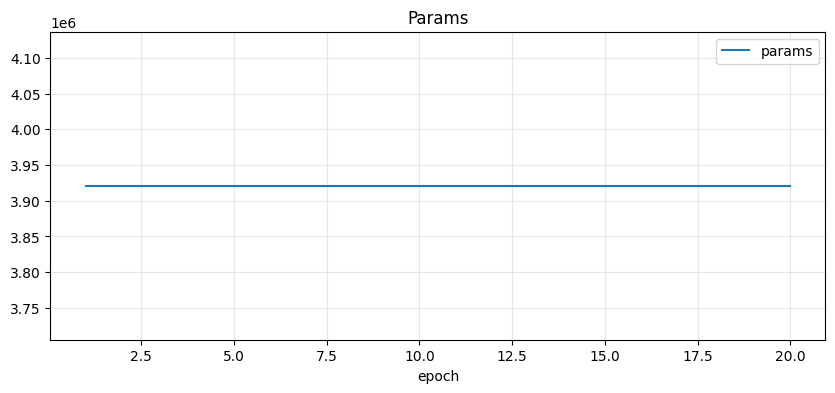

Epoch 23/100
----------
--- Cur phase: train


  7%|▋         | 44/632 [00:19<04:10,  2.34it/s, Loss=0.533762, Corrects=24/32, Accuracy=75.000%]/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|██████████| 632/632 [04:26<00:00,  2.37it/s, Loss=0.568493, Corrects=23/32, Accuracy=71.875%]


Calculating metrics...
train loss: 0.505819, acc: 0.749110, f05_macro: 0.749239, f1_macro: 0.749019
--- Cur phase: test


100%|██████████| 79/79 [00:15<00:00,  5.26it/s, Loss=0.260320, Corrects=1/1, Accuracy=100.000%]


Calculating metrics...
test loss: 0.523598, acc: 0.740088, f05_macro: 0.744304, f1_macro: 0.736485
--- Cur phase: val


100%|██████████| 70/70 [00:13<00:00,  5.26it/s, Loss=0.517780, Corrects=23/32, Accuracy=71.875%]


Calculating metrics...
val loss: 0.525941, acc: 0.733036, f05_macro: 0.736882, f1_macro: 0.728981
Проверка условия расширения...
Среднее изменение loss: 0.031455564356985564, порог: 0.005
p 3921026


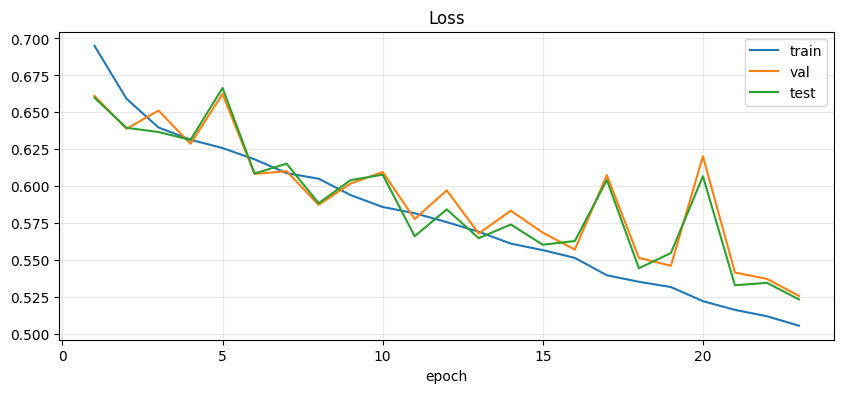

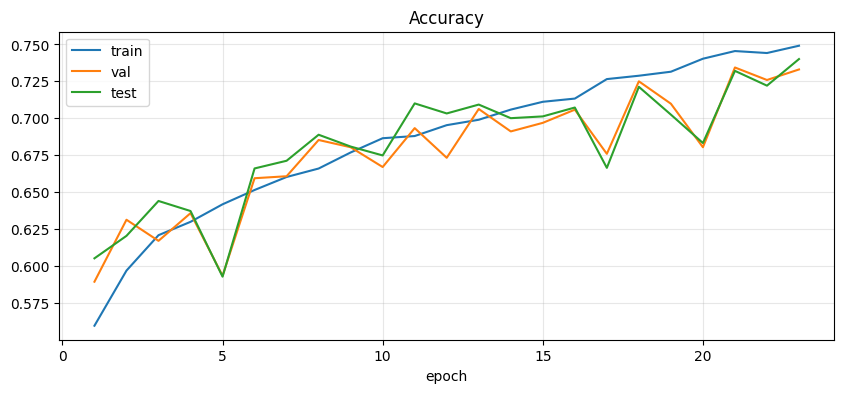

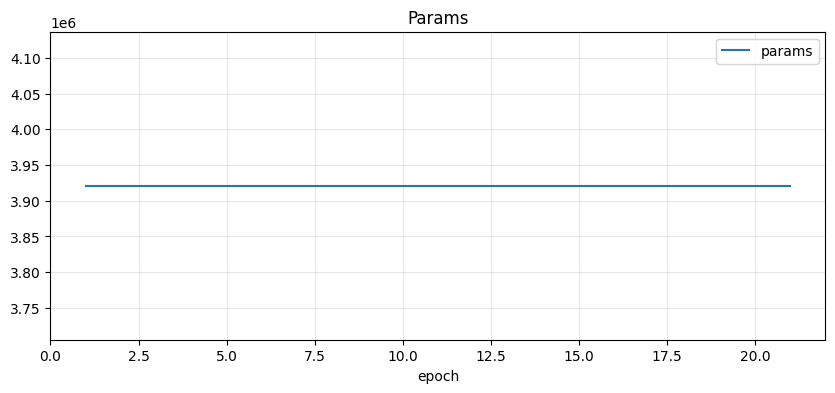

Epoch 24/100
----------
--- Cur phase: train


 28%|██▊       | 178/632 [01:16<03:12,  2.36it/s, Loss=0.526426, Corrects=23/32, Accuracy=71.875%]

In [ ]:
plot_every = 1
save_plots = True
plots_dir = "plots"
os.makedirs(plots_dir, exist_ok=True)
hyperparams = {
    "num_epochs": 100,
    "task_type": "classification",
    "edge_importance_metric": AbsGradientEdgeMetric(nn.CrossEntropyLoss()),
    "edge_score_aggregation": "mean",
    "max_new_edges_per_expansion": 100,
    "prune_after_epochs": 3,
    "min_epochs_between_expansions": 2,
    "plateau_window_size": 3,
    "plateau_threshold": 0.05,
    "start_fully_connected": False,
    "expansion_thresholds": {
        "qkv_layer_0": 0.15,
        "qkv_layer_1": 0.12,
        # "qkv_layer_2": 0.10,
        # "qkv_layer_3": 0.08,
    },
    "pruning_thresholds": {
        "qkv_layer_0": 0.08,
        "qkv_layer_1": 0.06,
        # "qkv_layer_2": 0.05,
        # "qkv_layer_3": 0.04,
    },
}

# Модель для Cats vs Dogs (2 класса)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model2 = SparseViT(
    num_classes=2,           # Cats vs Dogs
    img_size=224,
    patch_size=16,
    dim=384,                 # увеличено с 192 для лучшей точности
    depth=2,                 # 4 слоя QKV
    num_heads=6,             # dim=384 / head_dim=64
    channels=3,
    dropout=0.1,
    device=device,
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model2.parameters(),
    lr=3e-4,
    weight_decay=0.01,
    betas=(0.9, 0.999)
)



print("Model params:", get_params_amount(model2))
print("Starting training...")

losses, accs, f1s = train_vit_sparse(
    model=model2,
    dataloaders=dataloaders,
    criterion=criterion,
    optimizer=optimizer,
    hyperparams=hyperparams,
    device=device,
    num_epochs=100,
    experiment=None,
)
# Сохранение модели
torch.save({
    'model_state_dict': model2.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'hyperparams': hyperparams,
    'final_params': get_params_amount(model2)
}, 'sparse_vit_catsdogs_final.pth')

print("Training completed!")
print("Final params count:", get_params_amount(model2))


In [ ]:
# ================================
# Baseline: "обычный" ViT (dense QKV) для сравнения со SparseViT
# ================================

import torch
import torch.nn as nn
import torch.optim as optim


def make_dense_qkv_module(d_model, device):
    # Та же форма выхода, что и у sparse QKV: [B,N,d] -> [B,N,3d]
    # SimpleFCN (определён выше) делает reshape B*N, чтобы работало и для sparse, и для dense.
    return SimpleFCN(input_size=d_model, output_size=3 * d_model)


class DenseViT(nn.Module):
    """Архитектурно такой же как SparseViT, но QKV — обычный nn.Linear внутри SimpleFCN."""

    def __init__(
        self,
        num_classes,
        img_size=224,
        patch_size=16,
        dim=768,
        depth=2,
        num_heads=8,
        channels=3,
        dropout=0.1,
        device="cpu",
    ):
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2
        self.dim = dim

        self.patch_embeddings = nn.Conv2d(
            in_channels=channels,
            out_channels=dim,
            kernel_size=patch_size,
            stride=patch_size,
        )

        self.class_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.position_embeddings = nn.Parameter(torch.zeros(1, self.num_patches + 1, dim))

        self.encoder_blocks = nn.ModuleList()
        for i in range(depth):
            qkv_dense = make_dense_qkv_module(dim, device)
            setattr(self, f"qkv_layer_{i}", qkv_dense)  # для единообразия имён
            block = ViTEncoderBlock(dim, num_heads, qkv_dense, dropout=dropout)
            self.encoder_blocks.append(block)

        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(dim, num_classes)

    def forward(self, x, mask=None):
        x = self.patch_embeddings(x)  # [B, d, H', W']
        x = x.flatten(2).transpose(1, 2)  # [B, N, d]

        B = x.size(0)
        cls = self.class_token.expand(B, 1, -1)
        x = torch.cat([cls, x], dim=1)
        x = x + self.position_embeddings

        for block in self.encoder_blocks:
            x = block(x, mask)

        x = x[:, 0]
        x = self.dropout(x)
        return self.head(x)


def train_vit_dense(
    model,
    dataloaders,
    criterion,
    optimizer,
    device,
    num_epochs=5,
):
    """То же API/логи, что у train_vit_sparse, но без growth/prune."""
    model = model.to(device)

    phases = ["train", "test"]
    if "val" in dataloaders and "val" not in phases:
        phases.append("val")

    saved_epoch_losses = {p: [] for p in phases}
    saved_epoch_accuracies = {p: [] for p in phases}

    for epoch in range(1, num_epochs + 1):
        print("=" * 100)
        print(f"[DENSE] Epoch {epoch}/{num_epochs}")
        print("-" * 10)

        for phase in phases:
            print("--- Cur phase:", phase)
            if phase == "train":
                ep_loss, ep_acc, *_ = train_epoch(dataloaders[phase], model, criterion, optimizer, device)
            else:
                ep_loss, ep_acc, *_ = test_epoch(dataloaders[phase], model, criterion, optimizer, device)

            saved_epoch_losses[phase].append(ep_loss)
            saved_epoch_accuracies[phase].append(ep_acc)

            print(f"{phase} loss: {ep_loss:.6f}, acc: {ep_acc:.6f}")

    return saved_epoch_losses, saved_epoch_accuracies



In [ ]:
# ================================
# FashionMNIST: baseline DenseViT vs SparseViT (саморасширение)
# ================================

import os
import matplotlib.pyplot as plt
import torchvision.transforms as T
from torchvision.datasets import FashionMNIST
from torch.utils.data import DataLoader, random_split

# --- настройки эксперимента ---
FASHION_IMG_SIZE = 32
FASHION_PATCH = 4
FASHION_DIM = 128
FASHION_DEPTH = 2
FASHION_HEADS = 4
FASHION_DROPOUT = 0.1

batch_size = 64
num_workers = 2
val_ratio = 0.1

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- dataloaders FashionMNIST (полный, не обрезанный) ---
transform = T.Compose([
    T.Resize((FASHION_IMG_SIZE, FASHION_IMG_SIZE)),
    T.Grayscale(num_output_channels=3),
    T.ToTensor(),
    T.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

fashion_train_full = FashionMNIST(root='./data', train=True, download=True, transform=transform)
fashion_test = FashionMNIST(root='./data', train=False, download=True, transform=transform)

val_size = int(len(fashion_train_full) * val_ratio)
train_size = len(fashion_train_full) - val_size
train_ds, val_ds = random_split(fashion_train_full, [train_size, val_size])

fashion_dataloaders = {
    'train': DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=True, drop_last=True),
    'val': DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True, drop_last=True),
    'test': DataLoader(fashion_test, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True, drop_last=False),
}

# --- Baseline: DenseViT ---
print("\n==== Baseline DenseViT (FashionMNIST) ====")
dense_fashion = DenseViT(
    num_classes=10,
    img_size=FASHION_IMG_SIZE,
    patch_size=FASHION_PATCH,
    dim=FASHION_DIM,
    depth=FASHION_DEPTH,
    num_heads=FASHION_HEADS,
    channels=3,
    dropout=FASHION_DROPOUT,
    device=device,
).to(device)

criterion = nn.CrossEntropyLoss()
dense_opt = torch.optim.AdamW(dense_fashion.parameters(), lr=1e-4, weight_decay=0.01)

print("Dense params:", get_params_amount(dense_fashion))
dense_losses, dense_accs = train_vit_dense(
    model=dense_fashion,
    dataloaders=fashion_dataloaders,
    criterion=criterion,
    optimizer=dense_opt,
    device=device,
    num_epochs=10,
)

# --- SparseViT: саморасширение (без fully_connected) ---
print("\n==== SparseViT (FashionMNIST) + self-expansion ====")
plot_every = 1
save_plots = True
plots_dir = "plots_fashion_sparse"
os.makedirs(plots_dir, exist_ok=True)

hyperparams_fashion = {
    "num_epochs": 10,
    "task_type": "classification",
    "edge_importance_metric": AbsGradientEdgeMetric(nn.CrossEntropyLoss()),
    "edge_score_aggregation": "mean",
    "max_new_edges_per_expansion": 50,
    "prune_after_epochs": 2,
    "min_epochs_between_expansions": 1,
    "plateau_window_size": 2,
    "plateau_threshold": 0.001,
    "start_fully_connected": False,
    "expansion_thresholds": {
        "qkv_layer_0": 0.12,
        "qkv_layer_1": 0.12,
    },
    "pruning_thresholds": {
        "qkv_layer_0": 0.06,
        "qkv_layer_1": 0.06,
    },
}

sparse_fashion = SparseViT(
    num_classes=10,
    img_size=FASHION_IMG_SIZE,
    patch_size=FASHION_PATCH,
    dim=FASHION_DIM,
    depth=FASHION_DEPTH,
    num_heads=FASHION_HEADS,
    channels=3,
    dropout=FASHION_DROPOUT,
    device=device,
).to(device)

sparse_opt = torch.optim.AdamW(sparse_fashion.parameters(), lr=1e-4, weight_decay=0.01)

print("Sparse params (init):", get_params_amount(sparse_fashion))
sparse_losses, sparse_accs, sparse_f1 = train_vit_sparse(
    model=sparse_fashion,
    dataloaders=fashion_dataloaders,
    criterion=criterion,
    optimizer=sparse_opt,
    hyperparams=hyperparams_fashion,
    device=device,
    num_epochs=hyperparams_fashion["num_epochs"],
    experiment=None,
)

# --- Быстрые графики сравнения (val) ---
plt.figure(figsize=(10,4))
plt.plot(dense_losses.get('val', dense_losses['test']), label='Dense val/test')
plt.plot(sparse_losses.get('val', sparse_losses['test']), label='Sparse+expand val/test')
plt.title('FashionMNIST: Dense vs Sparse+expand (loss)')
plt.xlabel('epoch')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(10,4))
plt.plot(dense_accs.get('val', dense_accs['test']), label='Dense val/test')
plt.plot(sparse_accs.get('val', sparse_accs['test']), label='Sparse+expand val/test')
plt.title('FashionMNIST: Dense vs Sparse+expand (accuracy)')
plt.xlabel('epoch')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# ================================
# Cats vs Dogs baseline (DenseViT) — опционально
# ================================
# Чтобы сравнить с твоим SparseViT на CatsDogs (ячейка 97), включи флаг ниже.
RUN_DENSE_CATSDOGS = False
if RUN_DENSE_CATSDOGS:
    print("\n==== Baseline DenseViT (Cats vs Dogs) ====")
    # использует существующие dataloaders (CatsDogs) из ноутбука
    dense_cd = DenseViT(
        num_classes=2,
        img_size=224,
        patch_size=16,
        dim=384,
        depth=2,
        num_heads=6,
        channels=3,
        dropout=0.1,
        device=device,
    ).to(device)
    cd_opt = torch.optim.AdamW(dense_cd.parameters(), lr=3e-4, weight_decay=0.01, betas=(0.9,0.999))
    print("Dense params:", get_params_amount(dense_cd))
    cd_losses, cd_accs = train_vit_dense(
        model=dense_cd,
        dataloaders=dataloaders,
        criterion=nn.CrossEntropyLoss(),
        optimizer=cd_opt,
        device=device,
        num_epochs=10,
    )

